# Detecting and classifying radio protocols in spectrograms
### LTE, DMR, P25 and TETRA: data, training, evaluation and 20 inference scenarios

A 2.56 MHz wide capture is turned into a spectrogram. A YOLO26s detector draws a box around every transmission (where in time and frequency) and names its protocol. Everything here is read from the project's `runs/` and `logs/` folders, or regenerated with the project's own generator. Nothing is trained in this notebook.

| | Run 1 | Run 2 |
|---|---|---|
| Data it was trained on | `v0.3.0` pilot: 8 000 train scenes | `v0.4.0` main: 60 000 train scenes with IQ, distractors, harder receiver sessions |
| What was added | | mirror-image (IQ) filter, AM / CW / POCSAG distractors, "mid" impairment sessions, IQ features, unknown-signal rejection |

**How to read the numbers.** The saved evaluations (`logs/Evaluation_run*.ipynb`, `runs/evaluation/`) were executed on the frozen **v0.3.0 pilot test sets** for both runs, so run 1 and run 2 are directly comparable there. Those sets have no distractors, so Section 4.7 repeats the key tests on freshly regenerated **v0.4.0** test scenes, and Section 5 shows 20 hand-picked scenarios.

In [1]:
import os, sys, json, re, warnings, contextlib, io, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from IPython.display import display, Markdown, Image
import joblib

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
RUNS, LOGS = ROOT / "runs", ROOT / "logs"
RUN1 = dict(name="Run 1", det="detector_run1", clf="classifier_run1", gbm="baselines", log="Evaluation_run1.ipynb")
RUN2 = dict(name="Run 2", det="detector_run2", clf="classifier_run2", gbm="baselines_run2", log="Evaluation_run2.ipynb")
RUNS_ALL = [RUN1, RUN2]
C1, C2 = "#9aa5b1", "#2a6fdb"                                         # run 1 grey, run 2 blue
PROTO_COLOR = {"LTE": "#2a6fdb", "DMR": "#e8833a", "P25": "#3aa17e", "TETRA": "#b5434e"}
LIVE_SCALE = float(os.environ.get("PRESENTATION_LIVE_SCALE", "1"))   # e.g. 0.3 for a quick pass of the live checks
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def md(text):
    display(Markdown(text))


missing = [str(p) for r in RUNS_ALL for p in (RUNS / r["det"] / "best.pt", RUNS / r["clf"] / "best.pt", RUNS / "evaluation" / r["det"] / "summary.json", LOGS / r["log"]) if not p.exists()]
print("all run artifacts found" if not missing else f"missing: {missing}")

all run artifacts found


# 1. Task and approach

**Task.** Find every transmission in a 77 ms, 2.56 MHz capture and say which protocol it is.

| Protocol | Modulation | Channel | Time structure | What it looks like in a spectrogram |
|---|---|---|---|---|
| **LTE** | OFDM, 72 subcarriers x 15 kHz (1.4 MHz carrier) | about 1.1 MHz | 1 ms subframes, FDD or TDD | a wide striped block: bright control symbols every millisecond, data on a changing share of the resource blocks |
| **DMR** | 4FSK, 4800 sym/s, +-648 / +-1944 Hz | 12.5 kHz (about 6 bins) | 2-slot TDMA, 30 ms slots | a very narrow line: continuous (repeater) or 27.5 ms bursts (mobile) |
| **P25** | C4FM, 4800 sym/s, +-600 / +-1800 Hz | 12.5 kHz (about 6 bins) | continuous | a very narrow, continuous line |
| **TETRA** | pi/4-DQPSK, 18 ksym/s, RRC 0.35 | 25 kHz (about 17 bins) | 4-slot TDMA, 14.2 ms slots, 56.7 ms frame | a narrow band, continuous or in 14 ms slot bursts |

**Hard parts by design.** DMR and P25 are both 4800-baud 4-level FSK in the same channel width, so only burst timing and a few percent of deviation tell them apart. At the same SNR an LTE carrier is far more visible than a 7 kHz DMR channel, because the SNR is measured over each signal's own bandwidth. Other emitters (AM, CW, POCSAG) must be ignored, and signals never seen in training (NBFM, WFM, GSM) should not be called LTE / DMR / P25 / TETRA with confidence.

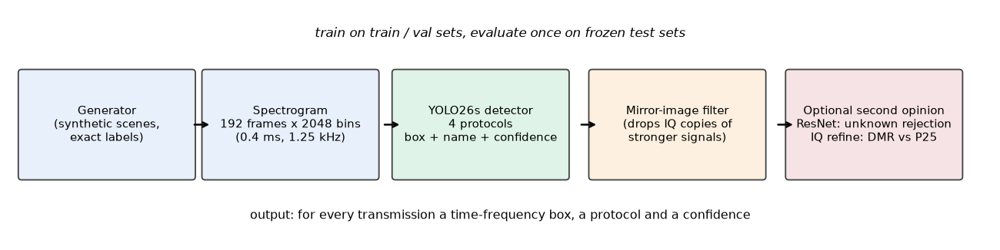

In [2]:
fig, ax = plt.subplots(figsize=(15, 3.6))
ax.set_xlim(0, 15); ax.set_ylim(0, 3.6); ax.axis("off"); ax.grid(False)
boxes = [(0.2, "Generator\n(synthetic scenes,\nexact labels)", "#e8f0fb"), (3.0, "Spectrogram\n192 frames x 2048 bins\n(0.4 ms, 1.25 kHz)", "#e8f0fb"),
         (5.9, "YOLO26s detector\n4 protocols\nbox + name + confidence", "#dff3e8"), (8.9, "Mirror-image filter\n(drops IQ copies of\nstronger signals)", "#fdf0e0"),
         (11.9, "Optional second opinion\nResNet: unknown rejection\nIQ refine: DMR vs P25", "#f6e3e5")]
for x, t, c in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.0), 2.6, 1.6, boxstyle="round,pad=0.05", fc=c, ec="#444", lw=1.2))
    ax.text(x + 1.3, 1.8, t, ha="center", va="center", fontsize=9.5)
for x in (2.85, 5.75, 8.75, 11.75):
    ax.annotate("", xy=(x + 0.25, 1.8), xytext=(x - 0.05, 1.8), arrowprops=dict(arrowstyle="->", lw=1.6))
ax.text(7.5, 3.15, "train on train / val sets, evaluate once on frozen test sets", ha="center", fontsize=11, style="italic")
ax.text(7.5, 0.35, "output: for every transmission a time-frequency box, a protocol and a confidence", ha="center", fontsize=10.5)
plt.show()

# 2. Data

The dataset is **synthetic and labelled automatically**: the generator knows the exact parameters of every signal. Each protocol is built at its own native rate with its real symbol clock, pulse shaping, framing and sync words, resampled to 2.56 MS/s, scaled to a requested SNR, passed through a receiver model (ADC, IQ imbalance, DC spike, band-edge roll-off) and turned into a spectrogram.

In [3]:
os.environ["SPECTRUM_PROFILE"] = "main"          # the sizes of the profile run 2 was trained on; nothing is written to disk
nb_src = json.loads((ROOT / "01_create_dataset.ipynb").read_text())
with contextlib.redirect_stdout(io.StringIO()):
    for idx in (1, 3, 5, 7, 9, 11, 13, 15):      # the generator cells of 01_create_dataset.ipynb, executed here (no copy of the code)
        src = "".join(nb_src["cells"][idx]["source"])
        src = src.split("_demo = make_specs")[0].split("# quick look at the envelopes")[0]
        exec(compile(src, f"01_create_dataset.ipynb[cell {idx}]", "exec"), globals())

from spectrum_common import (match_detections, box_iou_matrix, mirror_suppress, SNR_LABELS, snr_bin_labels)
from protocols import plan_activity

fmt_cfg = pd.Series({"sample rate": f"{FS / 1e6:.2f} MS/s complex", "band shown": f"{FS / 1e6:.2f} MHz", "FFT / bin width": f"{CFG.n_fft} / {DF:.0f} Hz",
                     "hop / frame period": f"{CFG.hop} samples / {CFG.hop / FS * 1e3:.2f} ms", "frames per scene": CFG.n_frames,
                     "scene duration": f"{NS / FS * 1e3:.1f} ms ({NS} samples)", "image": f"{CFG.n_frames} x {CFG.n_fft} (time x frequency)",
                     "SNR": f"{CFG.snr_range[0]:.0f} to {CFG.snr_range[1]:.0f} dB in-band (outside: stress set)", "dataset version": CFG.version})
display(fmt_cfg.to_frame("value"))

,value
sample rate,2.56 MS/s complex
band shown,2.56 MHz
FFT / bin width,2048 / 1250 Hz
hop / frame period,1024 samples / 0.40 ms
frames per scene,192
scene duration,77.2 ms (197632 samples)
image,192 x 2048 (time x frequency)
SNR,5 to 30 dB in-band (outside: stress set)
dataset version,0.4.0


## 2.1 One scene of each protocol
Each protocol alone at 25 dB. Top: the whole 2.56 MHz band. Bottom: zoom on the signal. White / yellow / cyan / lime boxes are the automatic labels (the 99% power band, and the frames in which the signal is on).

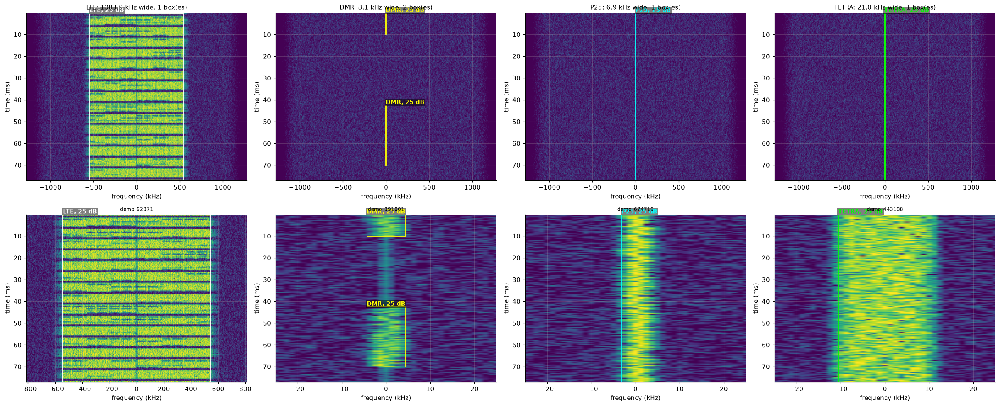

In [4]:
def new_scene(seed, force=None, session="train", irr_db=None, set_name="val"):
    """One scene from the project generator. force = [dict(cls, snr_db, fc_hz)] places exactly those signals, otherwise a random scene."""
    spec = make_specs(set_name, 0, 1)[0]
    spec.update(seed=int(seed), scene_id=f"demo_{int(seed) % 10**6}", mode="general")
    spec["session"] = session_for_group(SET_IDS[set_name], int(seed) % 30, session)
    if irr_db is not None:
        spec["session"]["irr_db"] = float(irr_db)
    if force:
        spec["force"] = force
    sc = make_scene(spec)
    sc["db"] = dequantize_db(sc["spec"])
    return sc


def box_to_axes(x0, y0, x1, y1):
    f0 = (x0 - CFG.n_fft / 2 - 0.5) * DF / 1e3
    f1 = (x1 - CFG.n_fft / 2 + 0.5) * DF / 1e3
    t0 = (y0 * CFG.hop + CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3
    t1 = (y1 * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3
    return f0, f1, t0, t1


def draw(ax, sc, preds=None, title=None, xlim=None, fs=9, extra=None):
    """Spectrogram with the ground truth (solid, protocol + SNR) and optional detections (dashed red, protocol + confidence)."""
    plot_scene(sc, ax=ax)
    [t.remove() for t in list(ax.texts)]
    for r in sc["signals"]:
        f0, f1, t0, t1 = box_to_axes(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"])
        ax.text(f0, t0, f'{r["class_name"]}, {r["snr_db"]:.0f} dB', color=FAM_COLORS[r["family_id"]], fontsize=fs, fontweight="bold", va="bottom",
                bbox=dict(fc="black", alpha=0.5, pad=1, lw=0))
    for k, d in enumerate(preds or []):
        f0, f1, t0, t1 = box_to_axes(*d["box"])
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="red", ls="--", lw=2))
        label = f"{FAMILIES[d['cls']]} {d['score']:.2f}" + (f" ({extra[k]})" if extra and extra[k] else "")
        ax.text(f1, t1, label, color="white", fontsize=fs, va="top", bbox=dict(fc="red", alpha=0.6, pad=1, lw=0))
    if xlim is not None:
        ax.set_xlim(*xlim)
    if title:
        ax.set_title(title, fontsize=10)


rng0 = np.random.default_rng(11)
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for k, name in enumerate(FAMILIES):
    sc = new_scene(int(rng0.integers(0, 2**62)), force=[dict(cls=name, snr_db=25.0, fc_hz=0.0)])
    r = sc["signals"][0]
    for row in (0, 1):
        draw(axes[row, k], sc, title=f"{name}: {r['obw_hz'] / 1e3:.1f} kHz wide, {len(sc['signals'])} box(es)" if row == 0 else None)
    half = max(25.0, 1.5 * r["obw_hz"] / 2e3)
    axes[1, k].set_xlim(-half, half)
plt.tight_layout()
plt.show()

## 2.2 Time structure: when each protocol is on the air
Grey = what is physically transmitted (e.g. each 27.5 ms DMR mobile burst, each TETRA slot), red = the label (bursts closer than 5 ms are one transmission = one box). Six random draws per protocol, 77 ms each. A push-to-talk call is far longer than the scene, so a call spans the whole scene or starts / stops inside it.

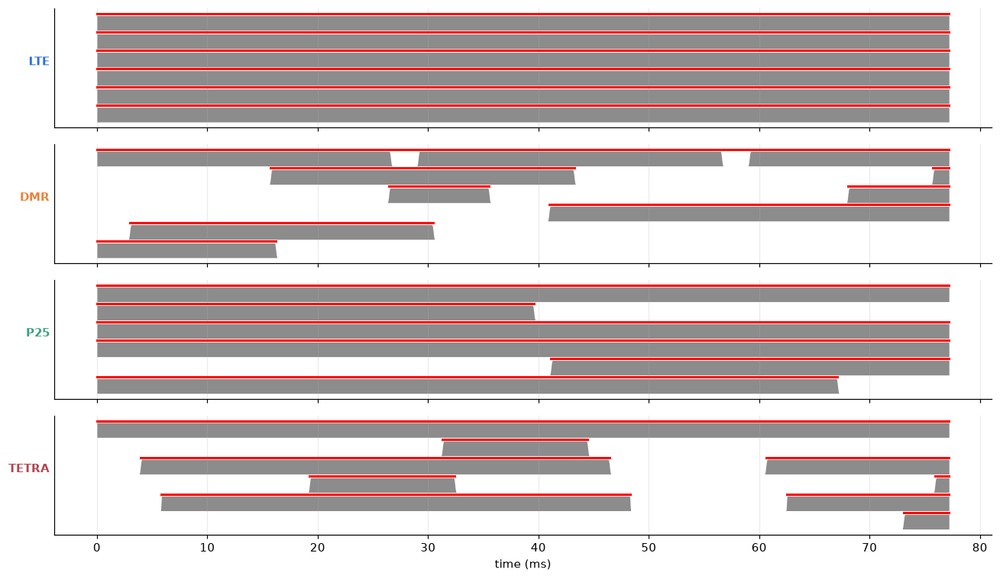

In [5]:
rng1 = np.random.default_rng(1)
fig, ax = plt.subplots(len(FAMILIES), 1, figsize=(12, 7), sharex=True)
for a, name in zip(ax, FAMILIES):
    for k in range(6):
        env_i, lab_i, info = plan_activity(rng1, name, NS, FS)
        a.fill_between(np.arange(NS) / FS * 1e3, k, k + 0.8 * envelope_from_intervals(env_i, NS), color="0.55", lw=0)
        for s0, s1 in lab_i:
            a.plot([s0 / FS * 1e3, s1 / FS * 1e3], [k + 0.9] * 2, color="red", lw=2)
    a.set_yticks([]); a.set_ylabel(name, rotation=0, ha="right", color=PROTO_COLOR[name], fontweight="bold")
ax[-1].set_xlabel("time (ms)")
plt.tight_layout()
plt.show()

## 2.3 Signals that are not labels: distractors and held-out signals
- **Distractors** (AM voice, CW carrier, POCSAG paging): present in 30% of the scenes of every set but **never labelled**, so the detector learns to ignore other emitters (run 2 only).
- **Held-out signals** (NBFM analog voice, WFM broadcast FM, GSM): appear **only** in the open-set test, to see what the models do with something they never saw.

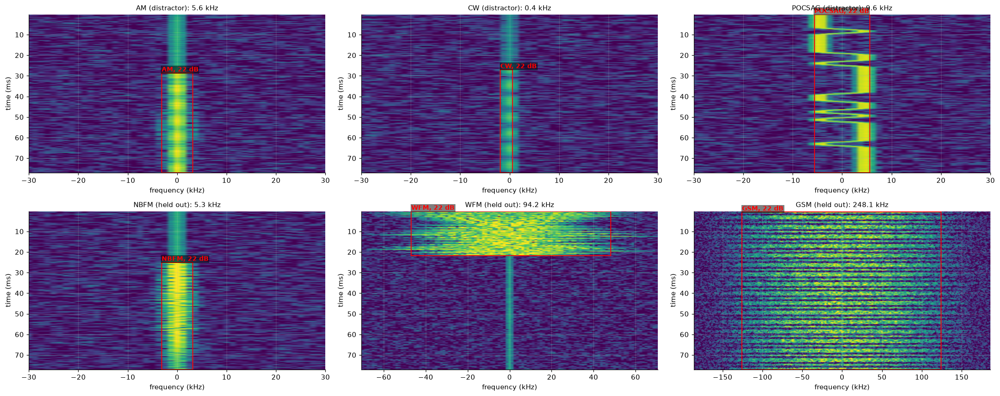

In [6]:
others = DISTRACT + UNKNOWN
rng2 = np.random.default_rng(5)
fig, axes = plt.subplots(2, 3, figsize=(20, 8))
for ax, name in zip(axes.ravel(), others):
    sc = new_scene(int(rng2.integers(0, 2**62)), force=[dict(cls=name, snr_db=22.0, fc_hz=0.0)])
    r = sc["signals"][0]
    draw(ax, sc, title=f"{name} ({'distractor' if name in DISTRACT else 'held out'}): {r['obw_hz'] / 1e3:.1f} kHz")
    half = max(30.0, 1.5 * r["obw_hz"] / 2e3)
    ax.set_xlim(-half, half)
plt.tight_layout()
plt.show()

## 2.4 The receiver changes how the same signals look
The same three signals through three kinds of receiver session. **Train**: 12 / 14-bit ADC, 25 to 50 dB image rejection. **Mid** (40% of the run-2 train sessions): 10-bit ADC, 5 ppm, 18 to 40 dB image rejection. **Hard** (`test_robust`, never trained on): 8-bit ADC, 10 ppm, Rayleigh fading. An IQ imbalance mirrors every signal about the centre at the image-rejection level, which a detector can mistake for another transmission.

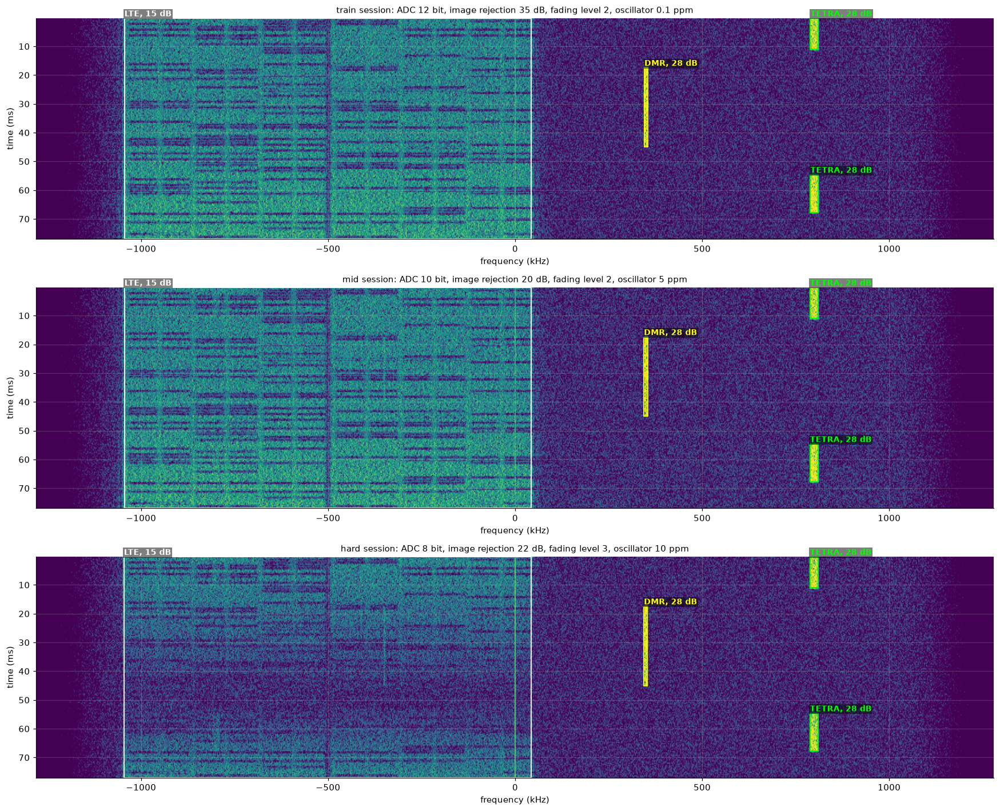

In [7]:
force = [dict(cls="LTE", snr_db=15.0, fc_hz=-500e3), dict(cls="DMR", snr_db=28.0, fc_hz=350e3), dict(cls="TETRA", snr_db=28.0, fc_hz=800e3)]
fig, axes = plt.subplots(3, 1, figsize=(16, 13))
for ax, (kind, irr) in zip(axes, (("train", None), ("mid", 20.0), ("hard", None))):
    sc = new_scene(777, force=force, session=kind, irr_db=irr)
    s = sc["scene"]
    draw(ax, sc, title=f"{kind} session: ADC {int(s['adc_bits'])} bit, image rejection {s['irr_db']:.0f} dB, fading level {int(s['fading_level'])}, oscillator {s['ppm']:g} ppm")
plt.tight_layout()
plt.show()

## 2.5 Sets, splits and size
Scenes are grouped into capture **sessions** of 50 scenes that share the receiver state; a session is never split between sets, and every set has its own seed range, so there is no leakage by construction. The frozen test sets are used once, for evaluation.

In [8]:
sizes = SET_SIZES_BY_PROFILE["main"]
purpose = {"train": "training (40% 'mid' sessions, SNR skewed to low values)", "val": "model selection, early stopping, thresholds", "test": "frozen: main test (uniform SNR 5-30 dB)",
           "test_robust": "frozen: unseen receiver (8-bit, 10 ppm, Rayleigh fading)", "test_openset": "frozen: held-out NBFM / WFM / GSM (+ distractors)",
           "test_snr_stress": "frozen: SNR outside 5-30 dB"}
tab = pd.DataFrame({"scenes (main)": sizes, "scenes (pilot)": SET_SIZES_BY_PROFILE["pilot"], "purpose": purpose})
tab["with IQ (GB)"] = (tab["scenes (main)"] * (CFG.n_frames * CFG.n_fft * 1.0 + NS * 4) / 1e9).round(1)
display(tab)
print(f"main: {sum(sizes.values()):,} scenes | spectrogram {CFG.n_frames * CFG.n_fft / 1e6:.2f} MB + raw IQ {NS * 4 / 1e6:.2f} MB per scene")

,scenes (main),scenes (pilot),purpose,with IQ (GB)
train,60000,8000,"training (40% 'mid' sessions, SNR skewed to lo...",71.0
val,10000,1500,"model selection, early stopping, thresholds",11.8
test,10000,1500,frozen: main test (uniform SNR 5-30 dB),11.8
test_robust,5000,1000,"frozen: unseen receiver (8-bit, 10 ppm, Raylei...",5.9
test_openset,5000,1000,frozen: held-out NBFM / WFM / GSM (+ distractors),5.9
test_snr_stress,5000,1000,frozen: SNR outside 5-30 dB,5.9


main: 95,000 scenes | spectrogram 0.39 MB + raw IQ 0.79 MB per scene


## 2.6 What the dataset contains (statistics)
Computed from the **first scenes of the real sets**: the generator is deterministic, so scene *i* of a set here is bit-identical to scene *i* of the stored dataset. 300 train and 150 val scenes.

450 scenes generated in 31 s


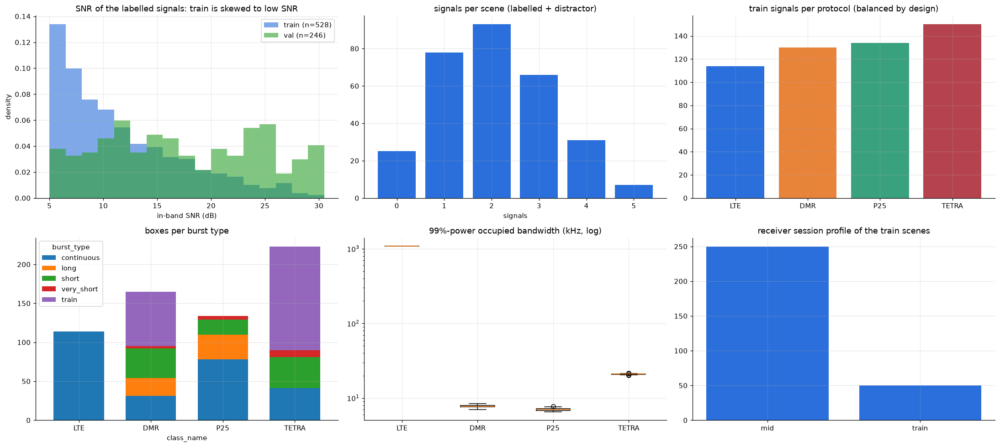

,signals,snr_mean,obw_kHz,box width (bins)
class_name,,,,
LTE,114,11.84,1085.07,869.0
DMR,130,11.51,7.78,7.0
P25,134,11.42,7.00,7.0
TETRA,150,11.78,20.93,18.0


scenes with a distractor: 93 of 300 (31%) | noise-only scenes: 25 | scenes with hard negatives (spur / impulse): 59


In [9]:
def collect(set_name, n):
    scs, rows = [], []
    for sp in make_specs(set_name, 0, n):
        sc = make_scene(sp)
        scs.append(sc["scene"]); rows += sc["signals"]
    return pd.DataFrame(scs), pd.DataFrame(rows)


t0 = time.time()
ST = {s: collect(s, max(int(n * LIVE_SCALE), 20)) for s, n in (("train", 300), ("val", 150))}
print(f"{sum(len(v[0]) for v in ST.values())} scenes generated in {time.time() - t0:.0f} s")
sc_tr, sg_tr = ST["train"]
sig_tr = sg_tr.drop_duplicates(["scene_id", "sig_idx"])
known = sig_tr[sig_tr.family_id <= len(FAMILIES)]
fig, ax = plt.subplots(2, 3, figsize=(20, 9))
for s, c in (("train", C2), ("val", "tab:green")):
    d = ST[s][1].drop_duplicates(["scene_id", "sig_idx"])
    d = d[d.family_id <= len(FAMILIES)]
    ax[0, 0].hist(d.snr_db, bins=np.arange(5, 31, 1.5), alpha=0.6, density=True, color=c, label=f"{s} (n={len(d)})")
ax[0, 0].set(title="SNR of the labelled signals: train is skewed to low SNR", xlabel="in-band SNR (dB)", ylabel="density"); ax[0, 0].legend()
ax[0, 1].bar(sc_tr.n_signals.value_counts().sort_index().index, sc_tr.n_signals.value_counts().sort_index().values, color=C2)
ax[0, 1].set(title="signals per scene (labelled + distractor)", xlabel="signals");
cnt = known.class_name.value_counts().reindex(FAMILIES)
ax[0, 2].bar(cnt.index, cnt.values, color=[PROTO_COLOR[p] for p in cnt.index]); ax[0, 2].set(title="train signals per protocol (balanced by design)")
bt = pd.crosstab(sg_tr[sg_tr.family_id <= len(FAMILIES)].class_name, sg_tr[sg_tr.family_id <= len(FAMILIES)].burst_type).reindex(FAMILIES)
bt[[c for c in ("continuous", "long", "short", "very_short", "train") if c in bt]].plot.bar(stacked=True, ax=ax[1, 0], rot=0, width=0.7)
ax[1, 0].set(title="boxes per burst type");
ax[1, 1].boxplot([known[known.class_name == p].obw_hz / 1e3 for p in FAMILIES]); ax[1, 1].set_xticklabels(FAMILIES)
ax[1, 1].set(title="99%-power occupied bandwidth (kHz, log)", yscale="log")
prof = np.select([sc_tr.adc_bits == 10, sc_tr.adc_bits == 8], ["mid", "hard"], "train")
ax[1, 2].bar(pd.Series(prof).value_counts().index, pd.Series(prof).value_counts().values, color=C2)
ax[1, 2].set(title="receiver session profile of the train scenes")
for a in ax.ravel():
    a.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

tbl = known.groupby("class_name").agg(signals=("snr_db", "size"), snr_mean=("snr_db", "mean"), obw_kHz=("obw_hz", lambda v: v.median() / 1e3)).reindex(FAMILIES)
tbl["box width (bins)"] = (sg_tr[sg_tr.family_id <= len(FAMILIES)].assign(w=lambda d: d.box_x1 - d.box_x0 + 1).groupby("class_name").w.median().reindex(FAMILIES))
display(tbl.round(2))
n_dist = sg_tr[sg_tr.family_id > len(FAMILIES)].scene_id.nunique()
print(f"scenes with a distractor: {n_dist} of {len(sc_tr)} ({100 * n_dist / len(sc_tr):.0f}%) | noise-only scenes: {int((sc_tr.n_signals == 0).sum())} | scenes with hard negatives (spur / impulse): {int((sc_tr.n_interferers > 0).sum())}")

**Labels and quality control.** A box is the frequency band holding 99% of the noise-free signal power times the frames in which the signal is on. The generator notebook checks box bounds and class ids, SNR range per set, held-out signals only in the open-set test, unique seeds, no session shared by two sets, the share of each signal's energy inside its box, and bit-for-bit reproducibility of regenerated scenes. Simulator validation: noise floor at 0 dB, SNR convention within 1 dB for every protocol, occupied bandwidths, 4FSK levels, DMR / TETRA slot timing and the LTE cyclic prefix.

# 3. Training

Three models were trained on `train` (model selection on `val` only; test sets untouched):

- **YOLO26s detector** (4 protocol classes, one stage: box + protocol), image 2048 x 192 pixels, frequency mirror and extra-noise augmentation only (scale / translate / mosaic would change the labels).
- **ResNet-18 classifier** on a 2-channel crop (spectrogram + box mask) of the whole time axis x 256 bins around a box, plus a calibrated energy threshold for unknown signals (run 2).
- **Gradient-boosting classifier (GBM)** on hand-crafted box features; run 2 adds IQ features (4FSK levels, sync words).

In [10]:
def read_args(run):
    a = {}
    for line in (RUNS / run["det"] / "train" / "args.yaml").read_text().splitlines():
        if ":" in line:
            k, v = line.split(":", 1)
            a[k.strip()] = v.strip()
    return a


rows = {}
for r in RUNS_ALL:
    a = read_args(r)
    res = pd.read_csv(RUNS / r["det"] / "train" / "results.csv"); res.columns = res.columns.str.strip()
    b = res["metrics/mAP50(B)"].idxmax()
    ch = json.load(open(RUNS / r["clf"] / "history.json")); cc = json.load(open(RUNS / r["clf"] / "config.json"))
    gm = json.load(open(RUNS / r["gbm"] / "val_metrics.json"))["feature_classifier_val"]
    gnames = joblib.load(RUNS / r["gbm"] / "feature_clf.joblib")["names"]
    rows[r["name"]] = {
        "training data": "v0.4.0 main" if "v0.4.0" in cc["root"] else ("v0.3.0 pilot" if "v0.3.0" in cc["root"] else cc["root"]),
        "YOLO model / image size": f'{a["model"].replace(".yaml", "")} / {a["imgsz"]}', "YOLO epochs run (max, patience)": f'{len(res)} ({a["epochs"]}, {a["patience"]})',
        "YOLO best epoch (val mAP50)": f'{int(res["epoch"][b])} ({res["metrics/mAP50(B)"].max():.3f})', "YOLO time per epoch": f'{res["time"].diff().median():.0f} s',
        "YOLO total time": f'{res["time"].iloc[-1] / 3600:.1f} h', "YOLO batch / device": f'{a["batch"]} / {a["device"]}',
        "ResNet epochs / best epoch / batch": f'{len(ch)} / {json.load(open(RUNS / r["clf"] / "val_metrics.json"))["best_epoch"]} / {cc["batch"]}',
        "ResNet time per epoch": f'{ch[0]["seconds"]:.0f} s', "GBM train / val boxes": f'{gm["train_boxes"]:,} / {gm["val_boxes"]:,}',
        "GBM features (IQ features)": f'{len(gnames)} ({"yes" if any(n.startswith("nb_") for n in gnames) else "no"})'}
display(pd.DataFrame(rows))

,Run 1,Run 2
training data,v0.3.0 pilot,v0.4.0 main
YOLO model / image size,yolo26s / 2048,yolo26s / 2048
"YOLO epochs run (max, patience)","60 (60, 25)","24 (40, 15)"
YOLO best epoch (val mAP50),27 (0.939),9 (0.932)
YOLO time per epoch,31 s,232 s
YOLO total time,0.5 h,1.5 h
YOLO batch / device,"16 / ""0""","16 / ""0"""
ResNet epochs / best epoch / batch,30 / 26 / 128,30 / 26 / 128
ResNet time per epoch,20 s,143 s
GBM train / val boxes,"16,804 / 3,130","125,439 / 21,186"


## 3.1 YOLO training curves
Left to right: box loss, classification loss, validation mAP50 and mAP50-95, precision and recall. Dots mark the best validation mAP50 (the weights that are kept). The two runs are validated on different validation sets (run 2's is harder: distractors, mid sessions), so compare the shape, not the absolute height.

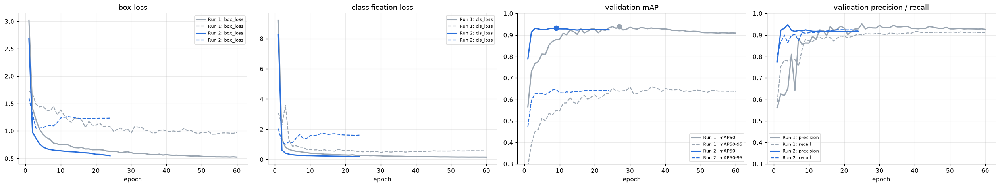

Run 1: 60 epochs, best mAP50 0.939 at epoch 27, last 0.909; mAP50-95 at best 0.639
Run 2: 24 epochs, best mAP50 0.932 at epoch 9, last 0.924; mAP50-95 at best 0.648


In [11]:
RES = {}
for r in RUNS_ALL:
    d = pd.read_csv(RUNS / r["det"] / "train" / "results.csv"); d.columns = d.columns.str.strip(); RES[r["name"]] = d
panels = [("train/box_loss", "val/box_loss", "box loss"), ("train/cls_loss", "val/cls_loss", "classification loss"), ("metrics/mAP50(B)", "metrics/mAP50-95(B)", "validation mAP"),
          ("metrics/precision(B)", "metrics/recall(B)", "validation precision / recall")]
fig, ax = plt.subplots(1, 4, figsize=(23, 4.4))
for a, (k1, k2, ttl) in zip(ax, panels):
    for name, c in (("Run 1", C1), ("Run 2", C2)):
        d = RES[name]
        a.plot(d.epoch, d[k1], color=c, lw=2, label=f"{name}: {k1.split('/')[-1].replace('(B)', '')}")
        a.plot(d.epoch, d[k2], color=c, lw=1.5, ls="--", label=f"{name}: {k2.split('/')[-1].replace('(B)', '')}")
        if "mAP" in ttl:
            b = d["metrics/mAP50(B)"].idxmax(); a.plot(d.epoch[b], d["metrics/mAP50(B)"][b], "o", color=c, ms=8)
    a.set(title=ttl, xlabel="epoch"); a.legend(fontsize=7)
    if "cls" in ttl:
        a.set_yscale("log")
    if "mAP" in ttl or "precision" in ttl:
        a.set_ylim(0.3, 1.0)
plt.tight_layout()
plt.show()
for name in ("Run 1", "Run 2"):
    d = RES[name]; b = d["metrics/mAP50(B)"].idxmax()
    print(f"{name}: {len(d)} epochs, best mAP50 {d['metrics/mAP50(B)'].max():.3f} at epoch {int(d.epoch[b])}, last {d['metrics/mAP50(B)'].iloc[-1]:.3f}; mAP50-95 at best {d['metrics/mAP50-95(B)'][b]:.3f}")

## 3.2 YOLO validation plots (best weights, written by Ultralytics at the end of training)
Normalized confusion matrix (rows = true protocol) and precision-recall curve on the validation set of each run.

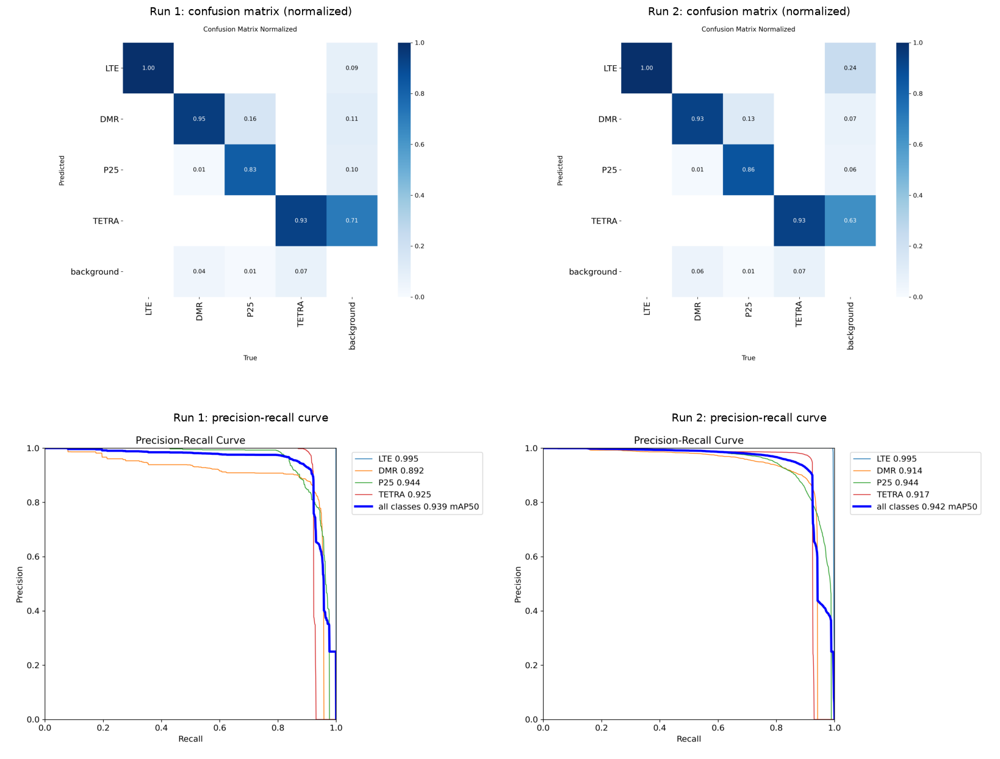

Run 1 validation: mAP50 0.939, mAP50-95 0.686, precision 0.954, recall 0.912
Run 2 validation: mAP50 0.942, mAP50-95 0.680, precision 0.936, recall 0.916


In [12]:
fig, ax = plt.subplots(2, 2, figsize=(15, 12))
for j, r in enumerate(RUNS_ALL):
    for i, (f, ttl) in enumerate((("confusion_matrix_normalized.png", "confusion matrix (normalized)"), ("BoxPR_curve.png", "precision-recall curve"))):
        ax[i, j].imshow(plt.imread(RUNS / r["det"] / "val" / f)); ax[i, j].axis("off"); ax[i, j].set_title(f'{r["name"]}: {ttl}'); ax[i, j].grid(False)
plt.tight_layout()
plt.show()
for r in RUNS_ALL:
    m = json.load(open(RUNS / r["det"] / "metrics_val.json"))
    print(f'{r["name"]} validation: mAP50 {m["map50"]:.3f}, mAP50-95 {m["map50_95"]:.3f}, precision {m["precision"]:.3f}, recall {m["recall"]:.3f}')

## 3.3 ResNet classifier and GBM
ResNet: training loss and validation accuracy / macro-F1 per epoch. GBM: validation per-protocol F1. Run 2 also stores `calibration.json`: the energy-score threshold below which a box is rejected as *unknown*, chosen on the validation boxes of the four known protocols only (it keeps 95% of them), so the held-out signals stay held out.

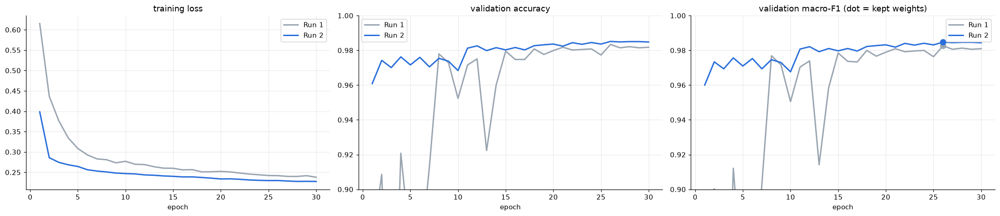

ResNet validation F1        GBM validation F1       
                     Run 1  Run 2             Run 1  Run 2
LTE                  1.000  1.000             1.000  1.000
DMR                  0.968  0.972             0.935  0.956
P25                  0.962  0.967             0.922  0.948
TETRA                1.000  1.000             1.000  0.999

unknown rejection (run 2): energy = logsumexp(logits) < 1.558 -> unknown; keeps 95% of the 21,186 known val boxes


In [13]:
H = {r["name"]: pd.DataFrame(json.load(open(RUNS / r["clf"] / "history.json"))) for r in RUNS_ALL}
fig, ax = plt.subplots(1, 3, figsize=(20, 4.4))
for name, c in (("Run 1", C1), ("Run 2", C2)):
    h = H[name]
    ax[0].plot(h.epoch, h.train_loss, color=c, lw=2, label=name)
    ax[1].plot(h.epoch, h.val_accuracy, color=c, lw=2, label=name)
    ax[2].plot(h.epoch, h.val_macro_f1, color=c, lw=2, label=name)
    b = h.val_macro_f1.idxmax(); ax[2].plot(h.epoch[b], h.val_macro_f1[b], "o", color=c, ms=8)
for a, t in zip(ax, ("training loss", "validation accuracy", "validation macro-F1 (dot = kept weights)")):
    a.set(title=t, xlabel="epoch"); a.legend()
ax[1].set_ylim(0.9, 1.0); ax[2].set_ylim(0.9, 1.0)
plt.tight_layout()
plt.show()

gbm_f1 = pd.DataFrame({r["name"]: {k: v["f1"] for k, v in json.load(open(RUNS / r["gbm"] / "val_metrics.json"))["feature_classifier_val"]["per_class"].items()} for r in RUNS_ALL})
res_f1 = pd.DataFrame({r["name"]: {k: v["f1"] for k, v in json.load(open(RUNS / r["clf"] / "val_metrics.json"))["per_class"].items()} for r in RUNS_ALL})
display(pd.concat({"ResNet validation F1": res_f1, "GBM validation F1": gbm_f1}, axis=1).round(3))
cal = json.load(open(RUNS / RUN2["clf"] / "calibration.json"))
print(f"unknown rejection (run 2): energy = logsumexp(logits) < {cal['energy_threshold']:.3f} -> unknown; keeps {cal['accept_known']:.0%} of the {cal['n_val_boxes']:,} known val boxes")

# 4. Evaluation

**Data used for Sections 4.1 to 4.6:** the saved evaluations in `runs/evaluation/*/summary.json`, `runs/detector_run*/diagnose_val.json` and `logs/Evaluation_run*.ipynb`. They were executed on the **frozen v0.3.0 pilot test sets** (test 1500, test_robust 1000, test_openset 1000, test_snr_stress 1000 scenes, no distractors) for **both** runs, so run 1 and run 2 are compared on identical data. The classical CFAR detector is left out. A detection counts when its box overlaps a true box with IoU >= 0.5; the end-to-end score also needs the right protocol.

Two caveats for run 2 on these sets: they contain no distractors (Section 4.7 measures those), and they contain no IQ, so the GBM (trained with IQ features) sees missing values and is weaker here than on its validation set.

,Run 1,Run 2,change
detection precision,0.964,0.995,0.030
detection recall,0.976,0.980,0.004
detection F1,0.970,0.987,0.017
class-aware F1 (best pipeline),0.950,0.975,0.025
"protocol accuracy, ResNet (GT boxes)",0.977,0.982,0.005
"protocol accuracy, GBM (GT boxes)",0.964,0.924,-0.039
detection F1 on test_robust,0.929,0.967,0.039
"open-set AUROC, ResNet energy",0.929,0.959,0.030


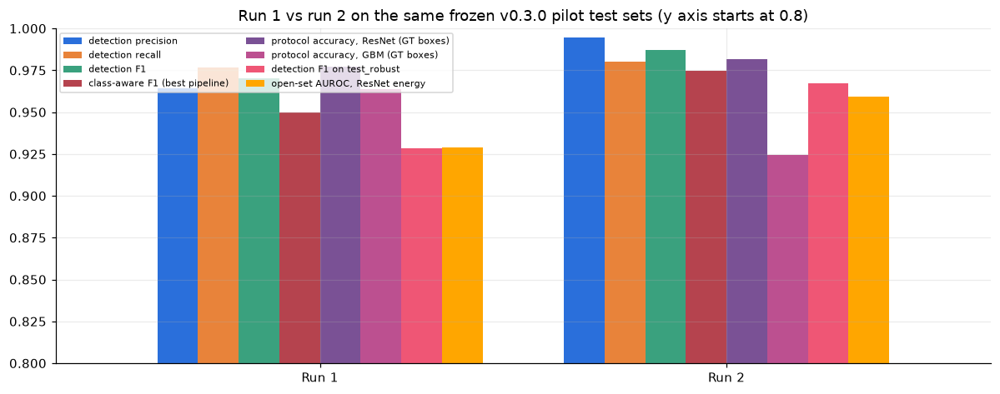

In [14]:
S = {r["name"]: json.load(open(RUNS / "evaluation" / r["det"] / "summary.json")) for r in RUNS_ALL}


def keep(df):
    return df[~df.index.astype(str).str.contains("CFAR")]


def row(name):
    s = S[name]
    best_cls = s["leaderboard"][s["best_pipeline"]]
    return {"detection precision": s["detectors"]["YOLO"]["precision"], "detection recall": s["detectors"]["YOLO"]["recall"], "detection F1": s["detectors"]["YOLO"]["f1"],
            "class-aware F1 (best pipeline)": best_cls["class_f1"], "protocol accuracy, ResNet (GT boxes)": s["classifiers"]["ResNet"]["accuracy"],
            "protocol accuracy, GBM (GT boxes)": s["classifiers"]["GBM"]["accuracy"],
            "detection F1 on test_robust": [r_ for r_ in s["robustness"] if r_["metric"] == "YOLO: detection F1"][0]["test_robust"],
            "open-set AUROC, ResNet energy": s["open_set"]["ResNet (energy)"]["auroc"]}


KEY = pd.DataFrame({n: row(n) for n in S})
KEY["change"] = KEY["Run 2"] - KEY["Run 1"]
display(KEY.round(3))
fig, ax = plt.subplots(figsize=(11, 4.4))
KEY[["Run 1", "Run 2"]].T.plot.bar(ax=ax, rot=0, width=0.8, color=[PROTO_COLOR["LTE"], PROTO_COLOR["DMR"], PROTO_COLOR["P25"], PROTO_COLOR["TETRA"], "#7a5195", "#bc5090", "#ef5675", "#ffa600"])
ax.set(ylim=(0.8, 1.0), title="Run 1 vs run 2 on the same frozen v0.3.0 pilot test sets (y axis starts at 0.8)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 4.1 Detection
How well the boxes are found and how precisely they sit. Recall, mean IoU and the false alarms per scene are measured on the validation set of the pilot data by `diagnose_detector.py` (YOLO only).

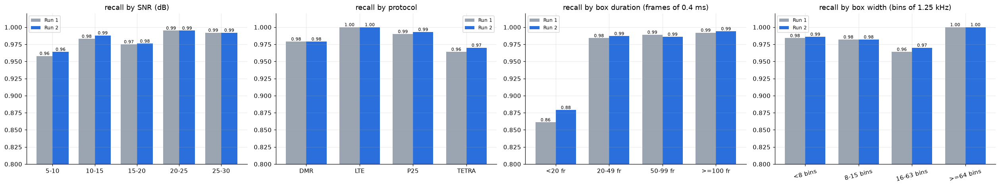

,Run 1,Run 2
true boxes,3130,3130
recall,0.98,0.983
mean IoU,0.936,0.93
left edge error (bins),0.381,0.397
right edge error (bins),0.403,0.412
start error (frames),0.198,0.11
end error (frames),0.269,0.161
protocol accuracy (matched),0.98,0.989
false alarms per scene,0.092,0.016


In [15]:
DG = {r["name"]: json.load(open(RUNS / r["det"] / "diagnose_val.json")) for r in RUNS_ALL}
fig, ax = plt.subplots(1, 4, figsize=(23, 4.4))
for a, key, ttl in zip(ax, ("snr_bin", "family", "dur_bin", "bw_bin"), ("recall by SNR (dB)", "recall by protocol", "recall by box duration (frames of 0.4 ms)", "recall by box width (bins of 1.25 kHz)")):
    t = {n: pd.DataFrame(DG[n][key]).set_index(key) for n in DG}
    idx = t["Run 2"].index
    if key == "snr_bin":
        idx = [x for x in SNR_LABELS if x in idx]
    x = np.arange(len(idx))
    for j, (n, c) in enumerate((("Run 1", C1), ("Run 2", C2))):
        b = a.bar(x + (j - 0.5) * 0.38, t[n].reindex(idx).recall, 0.38, color=c, label=n); a.bar_label(b, fmt="%.2f", fontsize=7)
    a.set_xticks(x, idx, rotation=0 if key != "bw_bin" else 15); a.set(ylim=(0.8, 1.02), title=ttl); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
box = pd.DataFrame({n: pd.DataFrame(DG[n]["all"]).iloc[0][["n", "recall", "mean_iou", "err_x0", "err_x1", "err_y0", "err_y1", "cls_acc"]] for n in DG})
box.loc["false alarms per scene"] = [DG[n]["false_positives_per_scene"] for n in DG]
box.index = ["true boxes", "recall", "mean IoU", "left edge error (bins)", "right edge error (bins)", "start error (frames)", "end error (frames)", "protocol accuracy (matched)", "false alarms per scene"]
display(box.round(3))

## 4.2 Protocol classification on ground-truth boxes
The classifiers are given the true boxes, so this isolates classification from detection. **LTE and TETRA are essentially perfect** (their bandwidth alone separates them); the errors are between **DMR and P25**.

In [16]:
def log_json(run):
    return json.load(open(LOGS / run["log"]))


def find_cell(nb, marker):
    return next(i for i, c in enumerate(nb["cells"]) if c["cell_type"] == "code" and marker in "".join(c["source"]))


def log_text(nb, i):
    out = []
    for o in nb["cells"][i].get("outputs", []):
        t = "".join(o["text"]) if o.get("output_type") == "stream" else "".join(o.get("data", {}).get("text/plain", ""))
        if t.strip():
            out.append(t)
    return out


def log_images(nb, i):
    import base64
    return [base64.b64decode(o["data"]["image/png"]) for o in nb["cells"][i].get("outputs", []) if "data" in o and "image/png" in o["data"]]


def parse_table(text):
    """text/plain of a small DataFrame (header line, optional index-name line, rows) -> DataFrame of floats."""
    lines = [l for l in text.splitlines() if l.strip()]
    cols = lines[0].split()
    data = {}
    for l in lines[1:]:
        tok = l.split()
        if len(tok) == len(cols) + 1:
            try:
                data[tok[0]] = [float(v) for v in tok[1:]]
            except ValueError:                                   # the index-name line, e.g. "SNR bin (dB)"
                continue
    return pd.DataFrame(data, index=cols).T


LOGS_NB = {r["name"]: log_json(r) for r in RUNS_ALL}
ci = {n: find_cell(nb, "GT_CACHE = {}") for n, nb in LOGS_NB.items()}
f1 = {}
for n, nb in LOGS_NB.items():
    t = next(x for x in log_text(nb, ci[n]) if "LTE" in x and "TETRA" in x)
    f1[n] = parse_table(t)
per_proto = pd.concat({n: f1[n] for n in f1}, axis=1)
display(per_proto.round(3))
cls_tab = pd.concat({n: pd.DataFrame(S[n]["classifiers"]).T[["accuracy", "macro_f1"]] for n in S}, axis=1)
display(cls_tab.round(3))

Run 1         Run 2       
         GBM ResNet    GBM ResNet
LTE    1.000  1.000  1.000  1.000
DMR    0.932  0.957  0.870  0.965
P25    0.913  0.945  0.784  0.957
TETRA  1.000  0.999  0.999  1.000

Run 1             Run 2         
       accuracy macro_f1 accuracy macro_f1
GBM       0.964    0.960    0.924    0.913
ResNet    0.977    0.975    0.982    0.980

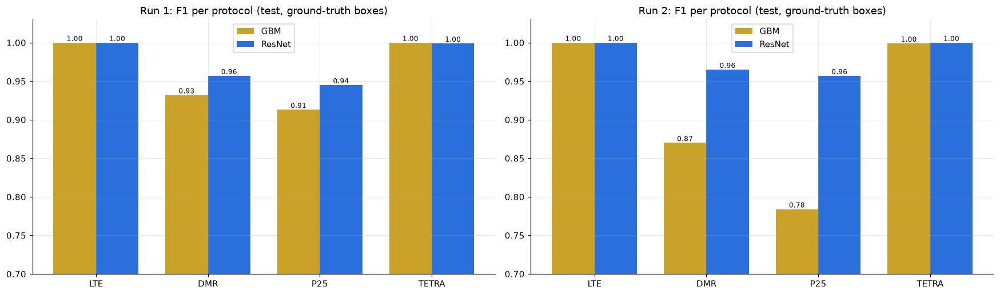

Confusion matrices on the test set, from the saved evaluation logs (rows = true protocol, left GBM, right ResNet):

**Run 1**

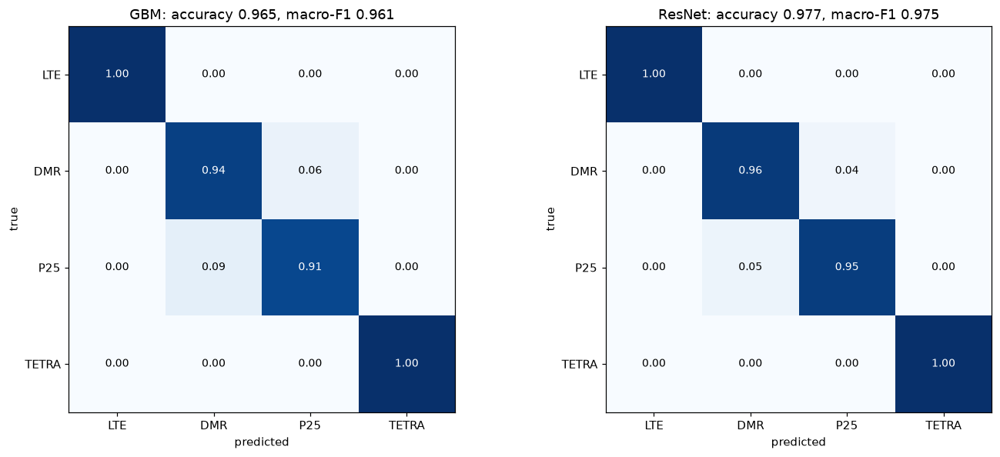

**Run 2**

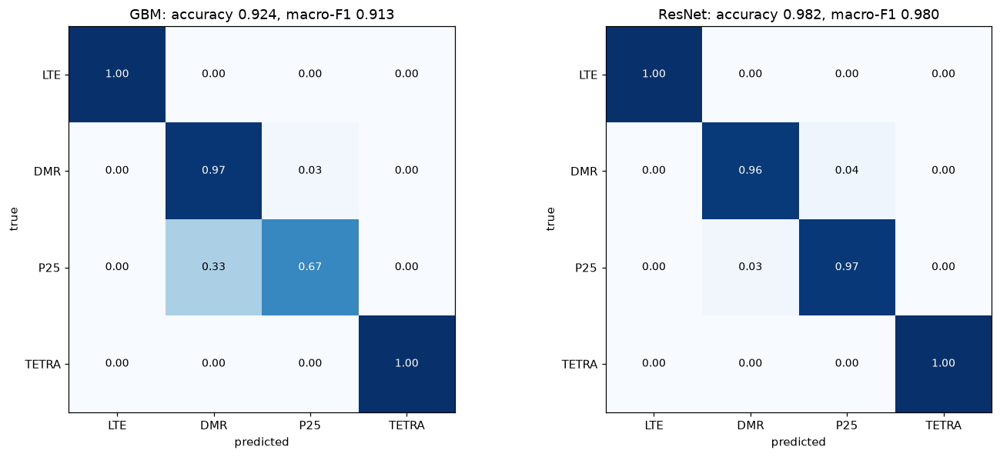

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
for a, n in zip(ax, ("Run 1", "Run 2")):
    t = f1[n]
    x = np.arange(len(t.index))
    for j, (c, col) in enumerate((("GBM", "#c9a227"), ("ResNet", C2))):
        b = a.bar(x + (j - 0.5) * 0.38, t[c], 0.38, label=c, color=col); a.bar_label(b, fmt="%.2f", fontsize=8)
    a.set_xticks(x, t.index); a.set(ylim=(0.7, 1.03), title=f"{n}: F1 per protocol (test, ground-truth boxes)"); a.legend()
plt.tight_layout(); plt.show()
md("Confusion matrices on the test set, from the saved evaluation logs (rows = true protocol, left GBM, right ResNet):")
for n, nb in LOGS_NB.items():
    imgs = log_images(nb, find_cell(nb, 'cm = np.array(m["confusion"]'))
    md(f"**{n}**")
    display(Image(imgs[0], width=1000))

## 4.3 End-to-end pipelines
A pipeline is a detector plus a way to name the protocol. **Class-aware F1** counts a prediction only if the box matches at IoU 0.5 *and* the protocol is right. The single-stage YOLO model wins in both runs: a separate classifier adds nothing.

,Run 1: det_f1,Run 1: class_f1,Run 1: cls_acc_on_matched,Run 2: det_f1,Run 2: class_f1,Run 2: cls_acc_on_matched
YOLO (single-stage),0.97,0.950,0.979,0.987,0.975,0.987
YOLO + ResNet,0.97,0.950,0.978,0.987,0.971,0.984
YOLO + GBM,0.97,0.927,0.956,0.987,0.897,0.908


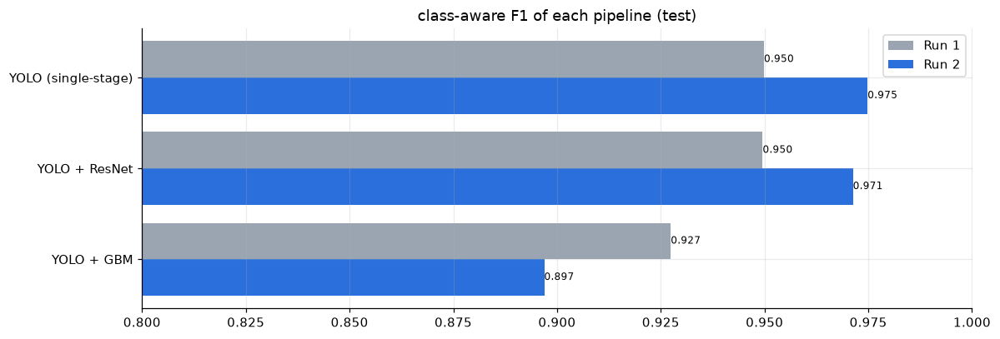

In [18]:
lb = pd.concat({n: keep(pd.DataFrame(S[n]["leaderboard"]).T)[["det_f1", "class_f1", "cls_acc_on_matched"]] for n in S}, axis=1)
lb.columns = [f"{a}: {b}" for a, b in lb.columns]
display(lb.sort_values("Run 2: class_f1", ascending=False).round(3))
fig, ax = plt.subplots(figsize=(11, 3.8))
p = keep(pd.DataFrame(S["Run 2"]["leaderboard"]).T)
q = keep(pd.DataFrame(S["Run 1"]["leaderboard"]).T)
x = np.arange(len(p)); order = p.index
b1 = ax.barh(x - 0.2, q.reindex(order).class_f1, 0.4, color=C1, label="Run 1"); b2 = ax.barh(x + 0.2, p.class_f1, 0.4, color=C2, label="Run 2")
ax.bar_label(b1, fmt="%.3f", fontsize=8); ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.set_yticks(x, order); ax.set(xlim=(0.8, 1.0), title="class-aware F1 of each pipeline (test)"); ax.invert_yaxis(); ax.legend()
plt.tight_layout(); plt.show()

## 4.4 Robustness to receiver conditions never seen in training
`test_robust` has a 10 ppm oscillator, an 8-bit ADC and Rayleigh fading. The big difference between the runs is in detection: run 1 lost 13 F1 points, run 2 about 2. The "no mirror filter" row shows the part of the gain that comes from training on the harder "mid" sessions alone; the rest is the mirror-image filter.

,Run 1: test,Run 1: test_robust,Run 2: test,Run 2: test_robust
metric,,,,
GBM: protocol accuracy,0.964,0.955,0.924,0.910
ResNet: protocol accuracy,0.977,0.974,0.982,0.979
YOLO (no mirror filter): detection F1,0.968,0.839,0.987,0.923
YOLO (single-stage) (best): class-aware F1,0.950,0.892,0.975,0.951
YOLO: detection F1,0.970,0.929,0.987,0.967


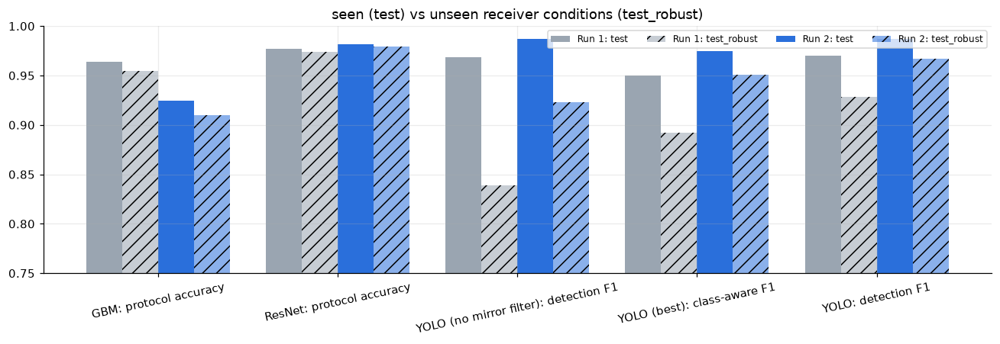

In [19]:
rob = pd.concat({n: keep(pd.DataFrame(S[n]["robustness"]).set_index("metric"))[["test", "test_robust"]] for n in S}, axis=1)
rob.columns = [f"{a}: {b}" for a, b in rob.columns]
display(rob.round(3))
metrics = [m for m in pd.DataFrame(S["Run 2"]["robustness"]).metric if "CFAR" not in m]
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(metrics)); w = 0.2
vals = {(n, s): [next(r_[s] for r_ in S[n]["robustness"] if r_["metric"] == m) if any(r_["metric"] == m for r_ in S[n]["robustness"]) else np.nan for m in metrics] for n in S for s in ("test", "test_robust")}
for j, ((n, s), v) in enumerate(vals.items()):
    ax.bar(x + (j - 1.5) * w, v, w, color=(C1 if n == "Run 1" else C2), alpha=1.0 if s == "test" else 0.55, label=f"{n}: {s}", hatch="" if s == "test" else "//")
ax.set_xticks(x, [m.replace(" (single-stage)", "") for m in metrics], rotation=12); ax.set(ylim=(0.75, 1.0), title="seen (test) vs unseen receiver conditions (test_robust)"); ax.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

## 4.5 Unknown signals (open set)
`test_openset` contains NBFM, WFM and GSM, which nothing was trained on. Three views: the **AUROC** of the classifiers' confidence scores (can the score tell known from unknown?), the **calibrated operating point** of run 2 (its energy threshold, set on validation data only), and how often the **detector fires** on each unknown signal.

,Run 1: auroc,Run 1: fpr_at_95_tpr,Run 2: auroc,Run 2: fpr_at_95_tpr
GBM (max-softmax),0.873,0.432,0.427,0.919
ResNet (max-softmax),0.828,0.930,0.934,0.151
ResNet (energy),0.929,0.257,0.959,0.089


,boxes,share
known protocols (test): kept,3142.0,0.945
NBFM (test_openset): rejected as unknown,388.0,0.580
WFM (test_openset): rejected as unknown,472.0,1.000
GSM (test_openset): rejected as unknown,434.0,0.394


boxes fire_rate most_common_label
YOLO NBFM   388  0.587629               P25
     WFM    472       0.0                 -
     GSM    434       0.0                 -

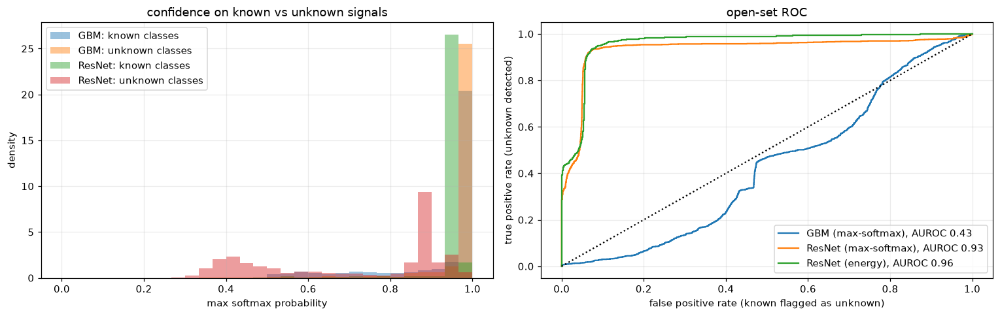

GBM: the open-set AUROC of run 2's GBM is below 0.5 here only because it was trained with IQ features that these test sets do not contain; ignore that row.

In [20]:
oo = pd.concat({n: pd.DataFrame(S[n]["open_set"]).T[["auroc", "fpr_at_95_tpr"]] for n in S}, axis=1)
oo.columns = [f"{a}: {b}" for a, b in oo.columns]
display(oo.round(3))
op = pd.DataFrame(S["Run 2"]["open_set_operating"]).T
op.columns = ["boxes", "share"]
display(op.round(3))
fr = pd.concat({d: pd.DataFrame(v).T for d, v in S["Run 2"]["unknown_fire_rate"].items() if "no mirror" not in d})
display(fr)
nb = LOGS_NB["Run 2"]
imgs = log_images(nb, find_cell(nb, "def ood_metrics"))
display(Image(imgs[0], width=1100))
md("GBM: the open-set AUROC of run 2's GBM is below 0.5 here only because it was trained with IQ features that these test sets do not contain; ignore that row.")

## 4.6 SNR stress and accuracy against SNR
Protocol accuracy on ground-truth boxes against SNR, over the test set (5 to 30 dB) and the stress set (below 5 and above 30 dB). Parsed from the evaluation logs. Accuracy is high above 5 dB and drops below it, where the training data stops.

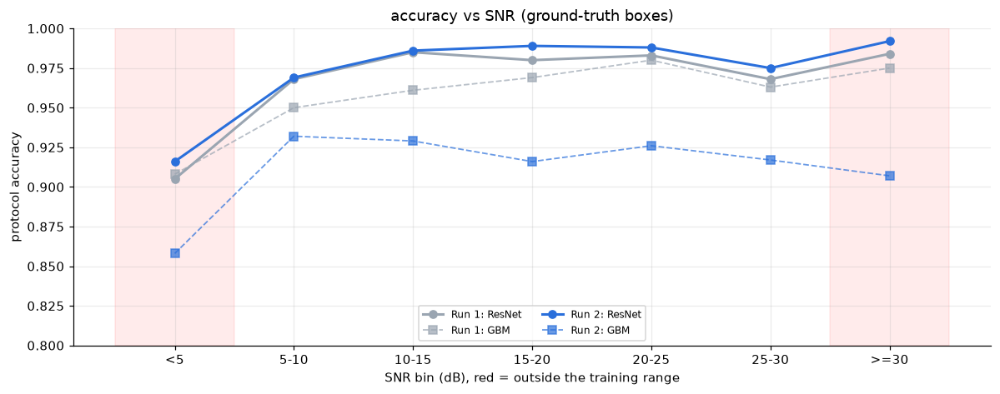

Run 1         Run 2       
         GBM ResNet    GBM ResNet
<5     0.908  0.905  0.858  0.916
5-10   0.950  0.968  0.932  0.969
10-15  0.961  0.985  0.929  0.986
15-20  0.969  0.980  0.916  0.989
20-25  0.980  0.983  0.926  0.988
25-30  0.963  0.968  0.917  0.975
>=30   0.975  0.984  0.907  0.992

In [21]:
snr_acc = {}
for n, nb in LOGS_NB.items():
    i = find_cell(nb, 'STRESS = "test_snr_stress"')
    t = next(x for x in log_text(nb, i) if "<5" in x and "ResNet" in x)
    snr_acc[n] = parse_table(t)
fig, ax = plt.subplots(figsize=(11, 4.4))
for n, c in (("Run 1", C1), ("Run 2", C2)):
    t = snr_acc[n]
    ax.plot(t.index, t["ResNet"], "o-", color=c, lw=2, label=f"{n}: ResNet")
    ax.plot(t.index, t["GBM"], "s--", color=c, lw=1.2, alpha=0.7, label=f"{n}: GBM")
ax.axvspan(-0.5, 0.5, color="red", alpha=0.08); ax.axvspan(5.5, 6.5, color="red", alpha=0.08)
ax.set(ylim=(0.8, 1.0), xlabel="SNR bin (dB), red = outside the training range", ylabel="protocol accuracy", title="accuracy vs SNR (ground-truth boxes)"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
display(pd.concat(snr_acc, axis=1).round(3))

## 4.7 Live check on regenerated v0.4.0 test scenes (distractors, hard receivers)
The saved evaluations cannot show how a model handles **distractors** (AM, CW, POCSAG), because the v0.3.0 test sets have none. Here the first scenes of the real **v0.4.0** test sets are regenerated (identical to the stored ones) and both runs' weights are applied. Detection only (YOLO at confidence 0.25); the *mirror filter* is applied after detection, so each run is shown with and without it. A detection that lands on a distractor or a held-out signal is a false alarm.

In [22]:
from train_detector import Detector
from train_classifier import classify_boxes, load_classifier, load_calibration, energy_score

LIVE_N = {"test": 300, "test_robust": 200, "test_openset": 200, "test_snr_stress": 200}
LIVE, t0 = {}, time.time()
for s, n in LIVE_N.items():
    lst = []
    for sp in make_specs(s, 0, max(int(n * LIVE_SCALE), 20)):
        sc = make_scene(sp)
        lst.append(dict(spec=sc["spec"], rows=sc["signals"], scene=sc["scene"]))
    LIVE[s] = lst
print(f"{sum(len(v) for v in LIVE.values())} scenes regenerated in {time.time() - t0:.0f} s")

DETS, t0 = {}, time.time()
for r in RUNS_ALL:
    det = Detector(RUNS / r["det"] / "best.pt", conf=0.05, mirror_filter=False)
    for s, lst in LIVE.items():
        raw = []
        for k in range(0, len(lst), 64):
            raw += det.detect_batch([dequantize_db(x["spec"]) for x in lst[k:k + 64]], conf=0.05)
        DETS[(r["name"], s, "no filter")] = raw
        DETS[(r["name"], s, "mirror filter")] = [mirror_suppress(d, dequantize_db(x["spec"])) for d, x in zip(raw, lst)]
print(f"detections for both runs in {time.time() - t0:.0f} s")


def evaluate(set_name, dets_all, conf=0.25, thr=0.5):
    tp = fp = fn = fp_other = right = 0
    recs = []
    for x, dets in zip(LIVE[set_name], dets_all):
        dets = [d for d in dets if d["score"] >= conf]
        gt = [r for r in x["rows"] if r["family_id"] <= len(FAMILIES)]
        unk = [r for r in x["rows"] if r["family_id"] > len(FAMILIES)]
        gb = [(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"]) for r in gt]
        ub = [(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"]) for r in unk]
        m = np.array(match_detections([d["box"] for d in dets], [d["score"] for d in dets], gb, thr)) if dets and gb else np.full(len(dets), -1)
        for p, d in enumerate(dets):
            if m[p] >= 0:
                tp += 1
                right += int(FAMILIES[d["cls"]] == gt[m[p]]["class_name"])
            else:
                fp += 1
                fp_other += int(bool(ub) and box_iou_matrix([d["box"]], ub).max() >= 0.3)
        fn += len(gb) - int((m >= 0).sum())
        for k, r in enumerate(gt):
            recs.append(dict(snr=r["snr_db"], found=bool((m == k).any())))
    n_sc = len(LIVE[set_name])
    return dict(precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), false_alarms_per_scene=fp / n_sc,
                fa_on_other_emitters=fp_other / n_sc, protocol_right_of_matched=right / max(tp, 1)), pd.DataFrame(recs)


EV = {(n, s, v): evaluate(s, DETS[(n, s, v)])[0] for n in ("Run 1", "Run 2") for s in LIVE for v in ("no filter", "mirror filter")}
live_tab = pd.DataFrame(EV).T
live_tab.index.names = ["run", "set", "mirror filter"]
display(live_tab.round(3))

900 scenes regenerated in 69 s
detections for both runs in 16 s


precision  recall     f1  \
run   set             mirror filter                             
Run 1 test            no filter          0.820   0.973  0.890   
                      mirror filter      0.839   0.973  0.901   
      test_robust     no filter          0.644   0.962  0.772   
                      mirror filter      0.821   0.962  0.886   
      test_openset    no filter          0.458   0.988  0.626   
                      mirror filter      0.478   0.988  0.644   
      test_snr_stress no filter          0.694   0.789  0.738   
                      mirror filter      0.826   0.789  0.807   
Run 2 test            no filter          0.992   0.968  0.980   
                      mirror filter      0.992   0.968  0.980   
      test_robust     no filter          0.868   0.962  0.912   
                      mirror filter      0.970   0.962  0.966   
      test_openset    no filter          0.586   0.988  0.736   
                      mirror filter      0.597   0.988  0.744   
      test_snr_stress no filter          0.908   0.785  0.842   
                      mirror filter      0.958   0.785  0.863   

                                     false_alarms_per_scene  \
run   set             mirror filter                           
Run 1 test            no filter                       0.450   
                      mirror filter                   0.393   
      test_robust     no filter                       1.250   
                      mirror filter                   0.495   
      test_openset    no filter                       0.945   
                      mirror filter                   0.875   
      test_snr_stress no filter                       0.900   
                      mirror filter                   0.430   
Run 2 test            no filter                       0.017   
                      mirror filter                   0.017   
      test_robust     no filter                       0.345   
                      mirror filter                   0.070   
      test_openset    no filter                       0.565   
                      mirror filter                   0.540   
      test_snr_stress no filter                       0.205   
                      mirror filter                   0.090   

                                     fa_on_other_emitters  \
run   set             mirror filter                         
Run 1 test            no filter                     0.217   
                      mirror filter                 0.217   
      test_robust     no filter                     0.220   
                      mirror filter                 0.220   
      test_openset    no filter                     0.685   
                      mirror filter                 0.685   
      test_snr_stress no filter                     0.105   
                      mirror filter                 0.105   
Run 2 test            no filter                     0.000   
                      mirror filter                 0.000   
      test_robust     no filter                     0.000   
                      mirror filter                 0.000   
      test_openset    no filter                     0.375   
                      mirror filter                 0.375   
      test_snr_stress no filter                     0.000   
                      mirror filter                 0.000   

                                     protocol_right_of_matched  
run   set             mirror filter                             
Run 1 test            no filter                          0.974  
                      mirror filter                      0.974  
      test_robust     no filter                          0.956  
                      mirror filter                      0.956  
      test_openset    no filter                          0.969  
                      mirror filter                      0.969  
      test_snr_stress no filter                          0.929  
                      mirror filter            

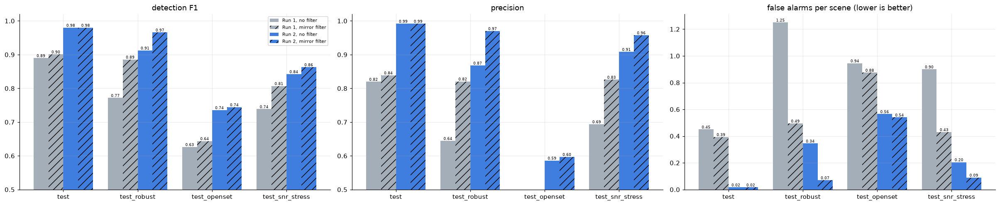

In [23]:
sets = list(LIVE)
variants = [("Run 1", "no filter", C1, ""), ("Run 1", "mirror filter", C1, "//"), ("Run 2", "no filter", C2, ""), ("Run 2", "mirror filter", C2, "//")]
fig, ax = plt.subplots(1, 3, figsize=(22, 4.6))
for a, metric, ttl in zip(ax, ("f1", "precision", "false_alarms_per_scene"), ("detection F1", "precision", "false alarms per scene (lower is better)")):
    for j, (n, v, c, h) in enumerate(variants):
        vals = [EV[(n, s, v)][metric] for s in sets]
        b = a.bar(np.arange(len(sets)) + (j - 1.5) * 0.2, vals, 0.2, color=c, hatch=h, alpha=0.9, label=f"{n}, {v}"); a.bar_label(b, fmt="%.2f", fontsize=6)
    a.set_xticks(range(len(sets)), sets); a.set(title=ttl)
    if metric != "false_alarms_per_scene":
        a.set_ylim(0.5, 1.02)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Run 1                             Run 2                            
       boxes fire_rate most_common_label boxes fire_rate most_common_label
signal                                                                    
AM        50      0.46               P25    50      0.00                 -
CW        53      0.00                 -    53      0.00                 -
POCSAG    42      0.81               DMR    42      0.00                 -
NBFM      77      1.00               P25    77      0.66               P25
WFM       98      0.00                 -    98      0.00                 -
GSM       73      0.00                 -    73      0.00                 -

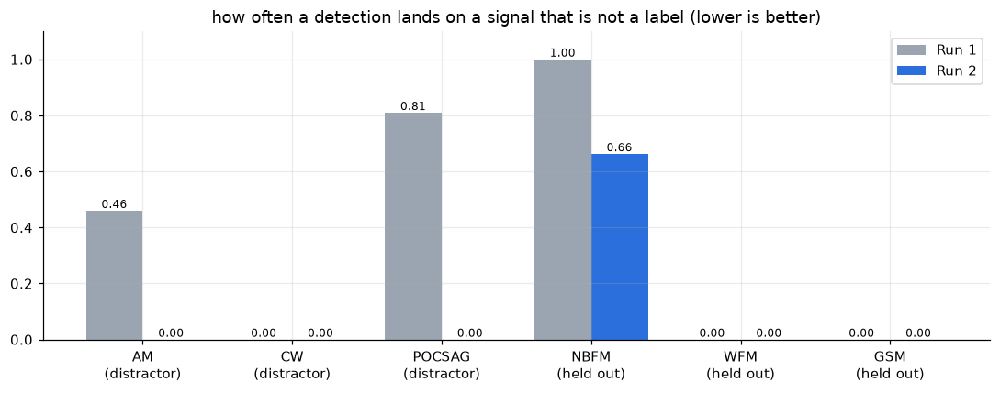

In [24]:
def fire_rates(run, variant="mirror filter"):
    rows = []
    for s in ("test", "test_openset"):
        for x, dets in zip(LIVE[s], DETS[(run, s, variant)]):
            dets = [d for d in dets if d["score"] >= 0.25]
            for r in x["rows"]:
                if r["family_id"] <= len(FAMILIES):
                    continue
                b = (r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"])
                iou = box_iou_matrix([b], [d["box"] for d in dets])[0] if dets else np.array([])
                hit = iou.size > 0 and iou.max() >= 0.5
                rows.append(dict(signal=r["class_name"], fired=hit, label=FAMILIES[dets[int(iou.argmax())]["cls"]] if hit else None))
    d = pd.DataFrame(rows)
    return d.groupby("signal").agg(boxes=("fired", "size"), fire_rate=("fired", "mean"), most_common_label=("label", lambda v: v.mode().iat[0] if v.notna().any() else "-"))


FR = pd.concat({n: fire_rates(n) for n in ("Run 1", "Run 2")}, axis=1)
order = [c for c in DISTRACT + UNKNOWN if c in FR.index]
display(FR.loc[order].round(2))
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(order))
for j, (n, c) in enumerate((("Run 1", C1), ("Run 2", C2))):
    b = ax.bar(x + (j - 0.5) * 0.38, FR.loc[order, (n, "fire_rate")], 0.38, color=c, label=n); ax.bar_label(b, fmt="%.2f", fontsize=8)
ax.set_xticks(x, [f"{o}\n({'distractor' if o in DISTRACT else 'held out'})" for o in order]); ax.set(ylim=(0, 1.1), title="how often a detection lands on a signal that is not a label (lower is better)"); ax.legend()
plt.tight_layout(); plt.show()

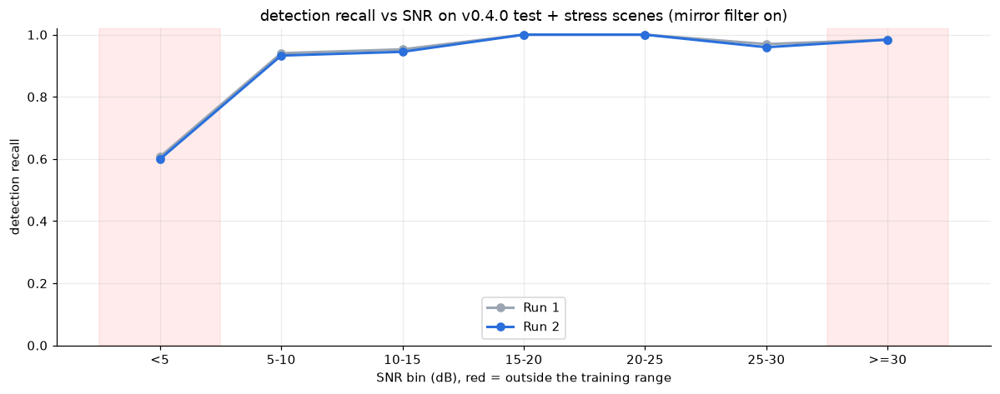

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.4))
for n, c in (("Run 1", C1), ("Run 2", C2)):
    recs = pd.concat([evaluate(s, DETS[(n, s, "mirror filter")])[1] for s in ("test", "test_snr_stress")])
    recs["bin"] = snr_bin_labels(recs.snr).to_numpy()
    rec = recs.groupby("bin", observed=True).found.mean().reindex(SNR_LABELS)
    ax.plot(SNR_LABELS, rec.values, "o-", color=c, lw=2, label=n)
ax.axvspan(-0.5, 0.5, color="red", alpha=0.08); ax.axvspan(5.5, 6.5, color="red", alpha=0.08)
ax.set(ylim=(0, 1.02), xlabel="SNR bin (dB), red = outside the training range", ylabel="detection recall", title="detection recall vs SNR on v0.4.0 test + stress scenes (mirror filter on)"); ax.legend()
plt.tight_layout(); plt.show()

In [26]:
DEV = __import__("spectrum_common").pick_device()
rows, E = {}, {}
for r in RUNS_ALL:
    rn, ck = load_classifier(RUNS / r["clf"] / "best.pt", DEV)
    ys, yh, en_k = [], [], []
    for x in LIVE["test"]:
        kb = [rw for rw in x["rows"] if rw["family_id"] <= len(FAMILIES)]
        if not kb:
            continue
        lg = classify_boxes(rn, dequantize_db(x["spec"]), [(rw["box_x0"], rw["box_y0"], rw["box_x1"], rw["box_y1"]) for rw in kb], DEV)
        ys += [rw["family_id"] - 1 for rw in kb]; yh += list(lg.argmax(1)); en_k += list(energy_score(lg))
    en_u, cls_u = [], []
    for s in ("test", "test_openset"):
        for x in LIVE[s]:
            ub = [rw for rw in x["rows"] if rw["family_id"] > len(FAMILIES)]
            if ub:
                lg = classify_boxes(rn, dequantize_db(x["spec"]), [(rw["box_x0"], rw["box_y0"], rw["box_x1"], rw["box_y1"]) for rw in ub], DEV)
                en_u += list(energy_score(lg)); cls_u += [rw["class_name"] for rw in ub]
    ys, yh, en_k, en_u, cls_u = map(np.asarray, (ys, yh, en_k, en_u, cls_u))
    held = np.isin(cls_u, UNKNOWN)
    from sklearn.metrics import roc_auc_score
    rows[r["name"]] = {"protocol accuracy (test GT boxes)": float((ys == yh).mean()),
                       "AUROC energy (known vs held-out NBFM/WFM/GSM)": float(roc_auc_score(np.r_[np.zeros(len(en_k)), np.ones(held.sum())], -np.r_[en_k, en_u[held]]))}
    E[r["name"]] = (en_k, en_u, cls_u, load_calibration(RUNS / r["clf"]))
display(pd.DataFrame(rows).round(3))
en_k, en_u, cls_u, cal2 = E["Run 2"]
thr = cal2["energy_threshold"]
op2 = {"known protocols kept": float((en_k >= thr).mean())}
for c in DISTRACT + UNKNOWN:
    if (cls_u == c).any():
        op2[f"{c} rejected as unknown"] = float((en_u[cls_u == c] < thr).mean())
display(pd.Series(op2, name="share at the calibrated threshold").round(3).to_frame())

,Run 1,Run 2
protocol accuracy (test GT boxes),0.989,0.990
AUROC energy (known vs held-out NBFM/WFM/GSM),0.941,0.968


,share at the calibrated threshold
known protocols kept,0.957
AM rejected as unknown,0.840
CW rejected as unknown,0.642
POCSAG rejected as unknown,0.881
NBFM rejected as unknown,0.494
WFM rejected as unknown,1.000
GSM rejected as unknown,0.342


In [27]:
r1n, r2n = "Run 1", "Run 2"
md(f"""
**What the live check shows** (v0.4.0 scenes, detection at confidence 0.25).
- *Receiver conditions:* on `test_robust`, detection F1 is {EV[(r1n, 'test_robust', 'no filter')]['f1']:.3f} (run 1, no filter), {EV[(r1n, 'test_robust', 'mirror filter')]['f1']:.3f} (run 1 + filter), {EV[(r2n, 'test_robust', 'no filter')]['f1']:.3f} (run 2, no filter) and {EV[(r2n, 'test_robust', 'mirror filter')]['f1']:.3f} (run 2 + filter); false alarms per scene {EV[(r1n, 'test_robust', 'no filter')]['false_alarms_per_scene']:.2f} -> {EV[(r2n, 'test_robust', 'mirror filter')]['false_alarms_per_scene']:.2f}.
- *Distractors and unknown signals:* the share of AM / CW / POCSAG / NBFM / WFM / GSM boxes on which a detection lands (run 1 -> run 2): {", ".join(f"{c} {FR.loc[c, (r1n, 'fire_rate')]:.2f} -> {FR.loc[c, (r2n, 'fire_rate')]:.2f}" for c in order)}. Lower is better: these signals are not labels.
- NBFM analog voice looks like a narrow DMR / P25 line and none of the training distractors resembles it, so it is the case most likely to stay accepted.
""")


**What the live check shows** (v0.4.0 scenes, detection at confidence 0.25).
- *Receiver conditions:* on `test_robust`, detection F1 is 0.772 (run 1, no filter), 0.886 (run 1 + filter), 0.912 (run 2, no filter) and 0.966 (run 2 + filter); false alarms per scene 1.25 -> 0.07.
- *Distractors and unknown signals:* the share of AM / CW / POCSAG / NBFM / WFM / GSM boxes on which a detection lands (run 1 -> run 2): AM 0.46 -> 0.00, CW 0.00 -> 0.00, POCSAG 0.81 -> 0.00, NBFM 1.00 -> 0.66, WFM 0.00 -> 0.00, GSM 0.00 -> 0.00. Lower is better: these signals are not labels.
- NBFM analog voice looks like a narrow DMR / P25 line and none of the training distractors resembles it, so it is the case most likely to stay accepted.


# 5. Twenty inference scenarios

Each scenario is built with the project generator (exact protocol parameters, chosen SNR, chosen frequencies; the time structure is searched until it matches the description) and run through the **run-2 detector** (confidence 0.25, mirror filter on). Solid boxes = ground truth with protocol and SNR, dashed red = detections with protocol and confidence. For every detection the figure also shows the **ResNet** opinion (`CNN: x`, or `unknown?` when its energy score is below the calibrated threshold) and, for DMR / P25 boxes, the **IQ refinement** from the GBM trained with IQ features. The table at the end lists the outcome of all twenty and what the **run-1** detector (without the mirror filter, as evaluated before) did on the same scene.

In [28]:
import joblib
from baselines import FeatureClassifier

det2 = Detector(RUNS / RUN2["det"] / "best.pt", conf=0.25)                         # run 2, with the mirror filter
det1 = Detector(RUNS / RUN1["det"] / "best.pt", conf=0.25, mirror_filter=False)    # run 1 as it was evaluated (no filter)
rn2, _ = load_classifier(RUNS / RUN2["clf"] / "best.pt", DEV)
THR2 = load_calibration(RUNS / RUN2["clf"])["energy_threshold"]
GB2 = FeatureClassifier.load(RUNS / RUN2["gbm"] / "feature_clf.joblib")
CAN_REFINE = any(n.startswith("nb_") for n in GB2.names)
iDMR, iP25 = FAMILIES.index("DMR"), FAMILIES.index("P25")
print("run-2 detector, ResNet and GBM loaded | IQ refinement:", "available" if CAN_REFINE else "not available")


def pj(r):
    return json.loads(r["params_json"])


def first(rows, k=0):
    """First box of signal k."""
    return next(r for r in rows if r["sig_idx"] == k)


def find_scene(force, want=None, session="train", irr_db=None, tries=400, seed0=0):
    rg = np.random.default_rng(seed0)
    for _ in range(tries):
        sc = new_scene(int(rg.integers(0, 2**62)), force=force, session=session, irr_db=irr_db)
        if want is None or want(sc["signals"]):
            return sc
    raise RuntimeError("no scene matches the description")


def n_boxes(rows, k=0):
    return sum(1 for r in rows if r["sig_idx"] == k)


def second_opinions(sc, dets):
    """ResNet label / unknown flag and the IQ refinement (DMR vs P25) for every detection."""
    if not dets:
        return [], [], []
    boxes = [d["box"] for d in dets]
    lg = classify_boxes(rn2, sc["db"], boxes, DEV)
    cnn = [("unknown?" if e < THR2 else FAMILIES[int(l.argmax())]) for l, e in zip(lg, energy_score(lg))]
    refined = []
    iq = iq_to_complex(sc["iq"], sc["scene"]["iq_scale"])
    for d in dets:
        if CAN_REFINE and d["cls"] in (iDMR, iP25):
            p = GB2.predict_proba(sc["db"], [d["box"]], iq)[0]
            refined.append("DMR" if p[iDMR] >= p[iP25] else "P25")
        else:
            refined.append(None)
    return cnn, refined, lg


def run_scene(sc):
    d2 = det2.detect_batch([sc["db"]], conf=0.25)[0]
    d1 = det1.detect_batch([sc["db"]], conf=0.25)[0]
    return d2, d1


def outcome(sc, dets, expect):
    """found / right protocol / false alarms for the labelled signals; kind = protocols | silent | unknown."""
    gt = [r for r in sc["signals"] if r["family_id"] <= len(FAMILIES)]
    gb = [(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"]) for r in gt]
    m = np.array(match_detections([d["box"] for d in dets], [d["score"] for d in dets], gb, 0.5)) if dets and gb else np.full(len(dets), -1)
    found = len({int(g) for g in m if g >= 0})
    right = sum(1 for p, g in enumerate(m) if g >= 0 and FAMILIES[dets[p]["cls"]] == gt[g]["class_name"])
    fa = int((m < 0).sum())
    if expect == "protocols":
        verdict = "OK" if (found == len(gt) and right == found and fa == 0) else ("partly" if found > 0 else "FAIL")
    elif expect == "silent":
        verdict = "OK (silent)" if not dets else f"FAIL ({len(dets)} false alarm(s))"
    else:
        verdict = "rejected: no detection" if not dets else "fires as " + "/".join(sorted({FAMILIES[d["cls"]] for d in dets}))
    return dict(gt=len(gt), found=found, right=right, false_alarms=fa, verdict=verdict)

run-2 detector, ResNet and GBM loaded | IQ refinement: available


In [29]:
SCEN = [
    ("LTE, FDD carrier", "LTE 20 dB: the whole 1.1 MHz block, control symbols every ms", "protocols",
     dict(force=[dict(cls="LTE", snr_db=20.0, fc_hz=-200e3)], want=lambda s: pj(first(s))["duplex"] == "FDD")),
    ("LTE, TDD cell", "LTE 18 dB with silent uplink subframes: still one box", "protocols",
     dict(force=[dict(cls="LTE", snr_db=18.0, fc_hz=250e3)], want=lambda s: pj(first(s))["duplex"].startswith("TDD"))),
    ("DMR repeater downlink (continuous)", "DMR 22 dB, continuous 4FSK", "protocols",
     dict(force=[dict(cls="DMR", snr_db=22.0, fc_hz=-350e3)], want=lambda s: pj(first(s))["dmr_mode"] == "downlink")),
    ("DMR mobile, one slot (27.5 ms bursts)", "DMR 22 dB, bursts every 60 ms: several boxes", "protocols",
     dict(force=[dict(cls="DMR", snr_db=22.0, fc_hz=300e3)], want=lambda s: pj(first(s))["dmr_mode"] == "uplink_1slot" and n_boxes(s) >= 2)),
    ("DMR mobile, both slots", "DMR 22 dB, back-to-back bursts merged into one box", "protocols",
     dict(force=[dict(cls="DMR", snr_db=22.0, fc_hz=-150e3)], want=lambda s: pj(first(s))["dmr_mode"] == "uplink_2slot")),
    ("P25, continuous call", "P25 22 dB, one continuous line", "protocols",
     dict(force=[dict(cls="P25", snr_db=22.0, fc_hz=450e3)], want=lambda s: first(s)["burst_type"] == "continuous")),
    ("P25 call that starts inside the scene", "P25 20 dB, starts or ends mid-scene", "protocols",
     dict(force=[dict(cls="P25", snr_db=20.0, fc_hz=-450e3)], want=lambda s: first(s)["burst_type"] != "continuous")),
    ("TETRA base station main carrier", "TETRA 22 dB, always on, all four slots", "protocols",
     dict(force=[dict(cls="TETRA", snr_db=22.0, fc_hz=100e3)], want=lambda s: pj(first(s))["tetra_mode"] == "downlink_main")),
    ("TETRA mobile, one slot", "TETRA 22 dB, 13 ms bursts every 56.7 ms", "protocols",
     dict(force=[dict(cls="TETRA", snr_db=22.0, fc_hz=-400e3)], want=lambda s: pj(first(s))["tetra_mode"] == "uplink_1slot" and n_boxes(s) >= 2)),
    ("TETRA traffic carrier, several slots", "TETRA 22 dB, two or three active slots", "protocols",
     dict(force=[dict(cls="TETRA", snr_db=22.0, fc_hz=500e3)], want=lambda s: pj(first(s))["tetra_mode"] in ("downlink_partial", "uplink_multi"))),
    ("All four protocols in one scene", "LTE + DMR + P25 + TETRA side by side", "protocols",
     dict(force=[dict(cls="LTE", snr_db=18.0, fc_hz=-550e3), dict(cls="DMR", snr_db=25.0, fc_hz=330e3), dict(cls="P25", snr_db=25.0, fc_hz=620e3),
                 dict(cls="TETRA", snr_db=25.0, fc_hz=880e3)])),
    ("DMR next to P25 (the hard pair)", "two 4800-baud 4FSK channels 200 kHz apart", "protocols",
     dict(force=[dict(cls="DMR", snr_db=26.0, fc_hz=-100e3), dict(cls="P25", snr_db=26.0, fc_hz=100e3)],
          want=lambda s: pj(first(s, 0))["dmr_mode"] == "downlink" and first(s, 1)["burst_type"] == "continuous")),
    ("Narrowband signals at low SNR (6 to 8 dB)", "DMR + P25 + TETRA barely above the noise", "protocols",
     dict(force=[dict(cls="DMR", snr_db=7.0, fc_hz=-450e3), dict(cls="P25", snr_db=6.0, fc_hz=100e3), dict(cls="TETRA", snr_db=8.0, fc_hz=600e3)])),
    ("Strong signals, poor IQ image rejection (18 dB)", "DMR 30 dB + TETRA 30 dB: their mirror images must not be reported", "protocols",
     dict(force=[dict(cls="DMR", snr_db=30.0, fc_hz=500e3), dict(cls="TETRA", snr_db=30.0, fc_hz=-300e3)], irr_db=18.0)),
    ("Hard receiver (never trained): 8-bit, 10 ppm, Rayleigh fading", "LTE + DMR + TETRA through the test_robust receiver", "protocols",
     dict(force=[dict(cls="LTE", snr_db=18.0, fc_hz=-500e3), dict(cls="DMR", snr_db=22.0, fc_hz=250e3), dict(cls="TETRA", snr_db=22.0, fc_hz=700e3)], session="hard")),
    ("Distractors only: AM, CW, POCSAG", "three other emitters, nothing to detect: the detector must stay silent", "silent",
     dict(force=[dict(cls="AM", snr_db=20.0, fc_hz=-600e3), dict(cls="CW", snr_db=20.0, fc_hz=-100e3), dict(cls="POCSAG", snr_db=20.0, fc_hz=500e3)])),
    ("Unknown: NBFM analog voice", "never seen, looks like a narrow line: the hard open-set case", "unknown",
     dict(force=[dict(cls="NBFM", snr_db=22.0, fc_hz=200e3)])),
    ("Unknown: WFM broadcast FM and GSM", "never seen, 200 kHz wide: should not be named", "unknown",
     dict(force=[dict(cls="WFM", snr_db=20.0, fc_hz=-600e3), dict(cls="GSM", snr_db=20.0, fc_hz=500e3)])),
    ("Crowded scene with a distractor", "LTE + DMR + P25 + TETRA + a POCSAG distractor", "protocols",
     dict(force=[dict(cls="LTE", snr_db=14.0, fc_hz=-480e3), dict(cls="DMR", snr_db=18.0, fc_hz=180e3), dict(cls="P25", snr_db=18.0, fc_hz=400e3),
                 dict(cls="TETRA", snr_db=18.0, fc_hz=650e3), dict(cls="POCSAG", snr_db=18.0, fc_hz=950e3)])),
    ("A random scene from the open-set test", "scene taken from the v0.4.0 test_openset set", "random", {}),
]
assert len(SCEN) == 20

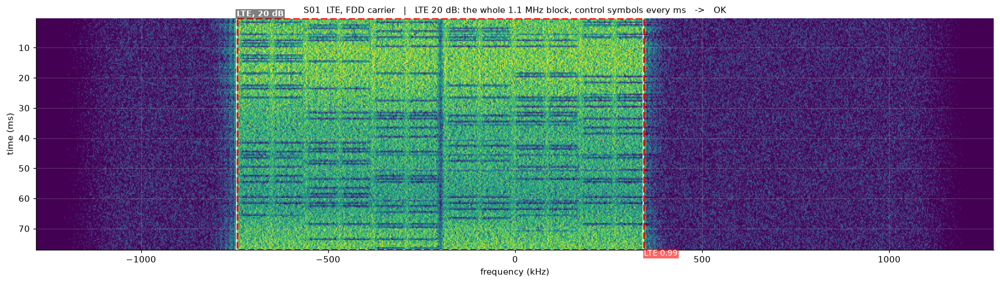

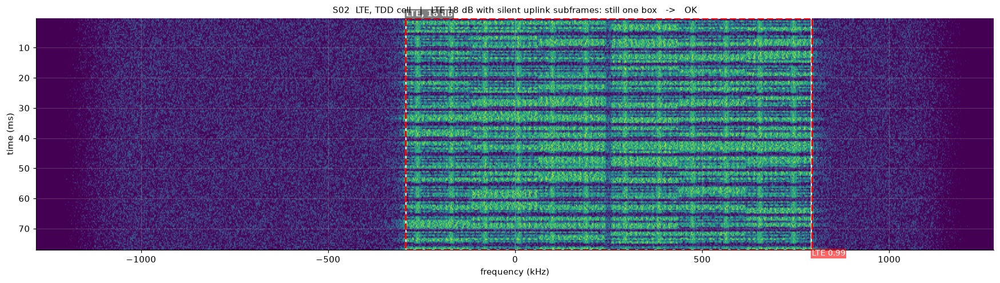

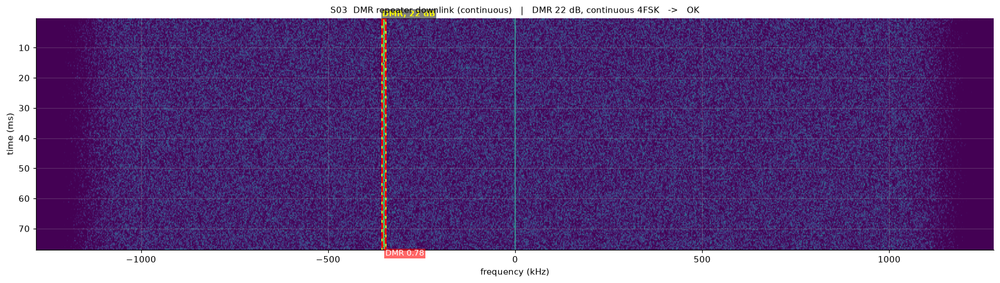

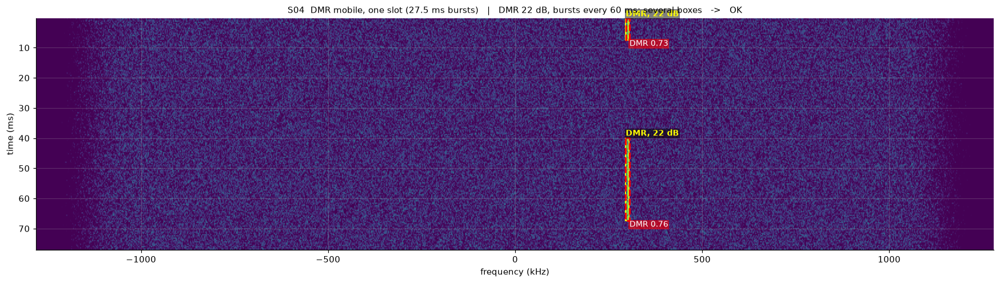

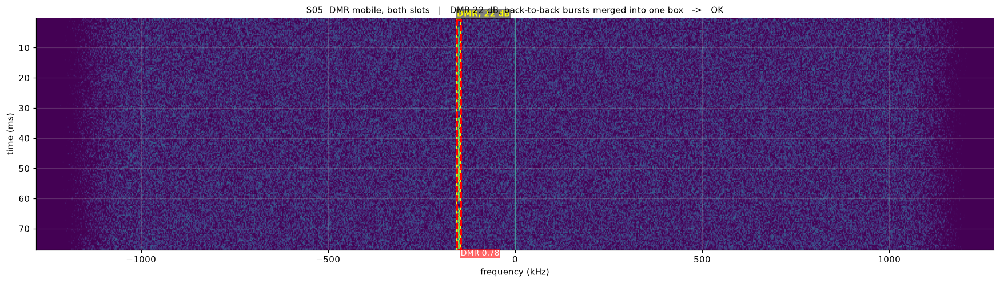

...

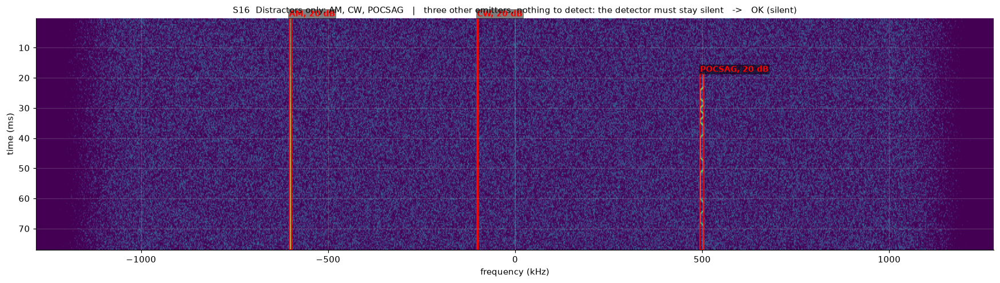

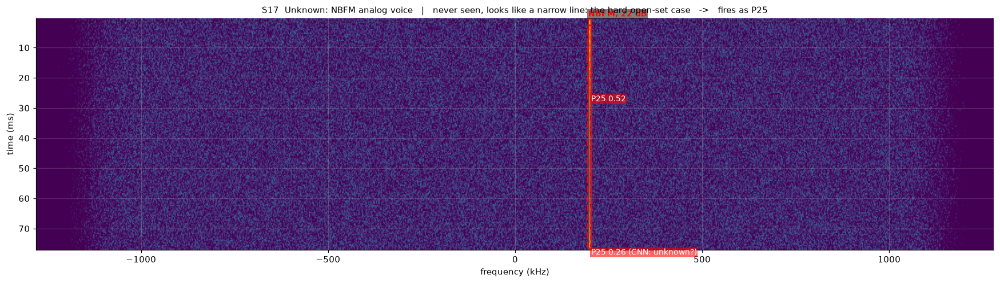

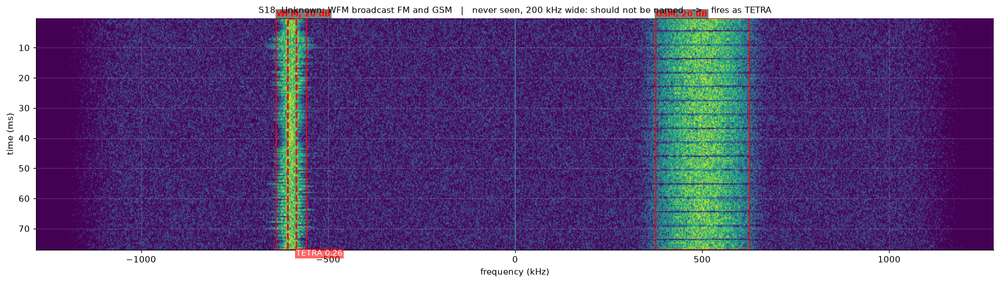

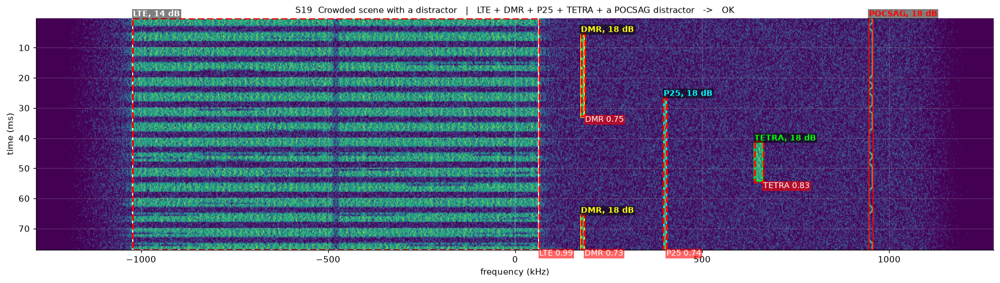

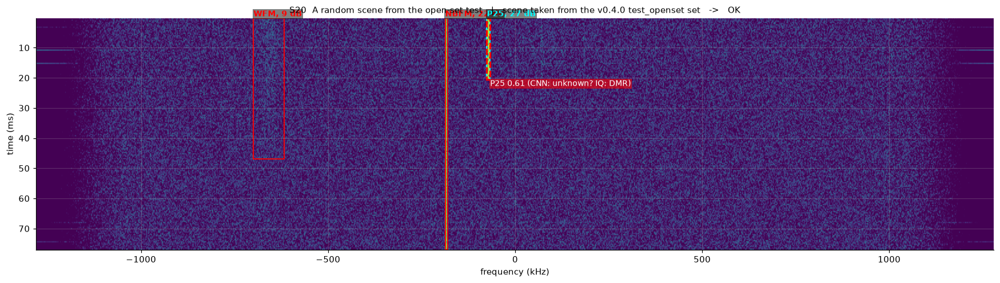

20 scenarios in 6 s


In [30]:
RESULTS = []
t0 = time.time()
for k, (title, expect_txt, expect, spec) in enumerate(SCEN, 1):
    if expect == "random":
        sc = None
        for i in range(60):
            sp = make_specs("test_openset", i, i + 1)[0]
            cand = make_scene(sp); cand["db"] = dequantize_db(cand["spec"])
            if cand["scene"]["n_signals"] >= 3 and any(r["family_id"] > len(FAMILIES) for r in cand["signals"]) and any(r["family_id"] <= len(FAMILIES) for r in cand["signals"]):
                sc = cand; break
        expect_kind = "protocols"
    else:
        sc = find_scene(spec["force"], spec.get("want"), spec.get("session", "train"), spec.get("irr_db"), seed0=k)
        expect_kind = expect
    d2, d1 = run_scene(sc)
    cnn, refined, _ = second_opinions(sc, d2)
    o2, o1 = outcome(sc, d2, expect_kind), outcome(sc, d1, expect_kind)
    notes = []
    for d, c, r_ in zip(d2, cnn, refined):
        yolo = FAMILIES[d["cls"]]
        parts = ([f"CNN: {c}"] if c != yolo else []) + ([f"IQ: {r_}"] if r_ and r_ != yolo else [])
        notes.append(" ".join(parts) or None)
    fig, ax = plt.subplots(figsize=(16, 4.6))
    draw(ax, sc, d2, title=f"S{k:02d}  {title}   |   {expect_txt}   ->   {o2['verdict']}", extra=notes)
    plt.tight_layout(); plt.show()
    RESULTS.append(dict(n=k, scenario=title, expected=expect_txt, labelled_boxes=o2["gt"], found=o2["found"], protocol_right=o2["right"], false_alarms=o2["false_alarms"],
                        detections=", ".join(f"{FAMILIES[d['cls']]} {d['score']:.2f}" for d in d2) or "-", unknown_flag=", ".join(c for c in cnn if c == "unknown?") or "",
                        verdict=o2["verdict"], run1_detections=len(d1), run1_false_alarms=o1["false_alarms"], run1_verdict=o1["verdict"]))
print(f"20 scenarios in {time.time() - t0:.0f} s")

## 5.1 All twenty scenarios in one table
`found` counts labelled signals matched at IoU 0.5, `protocol_right` those named correctly, `false_alarms` detections that match nothing. For *unknown* scenarios the verdict says whether the detector stayed silent or which protocol it fired as. The `run1_*` columns are the run-1 detector (no mirror filter) on exactly the same scene.

In [ ]:
R = pd.DataFrame(RESULTS).set_index("n")
pd.set_option("display.max_colwidth", 60, "display.width", 250)
display(R[["scenario", "labelled_boxes", "found", "protocol_right", "false_alarms", "verdict", "run1_false_alarms", "run1_verdict"]])
known = R[R.labelled_boxes > 0]
ok = (R.verdict.str.startswith("OK")).sum()
print(f"run 2: {ok} of 20 scenarios fully correct | labelled signals found {int(known.found.sum())} of {int(known.labelled_boxes.sum())}, named correctly {int(known.protocol_right.sum())} | "
      f"false alarms {int(R.false_alarms.sum())} (run 1 without the filter: {int(R.run1_false_alarms.sum())})")
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(R))
ax.bar(x - 0.2, R.run1_false_alarms, 0.4, color=C1, label="run 1 (no mirror filter)"); ax.bar(x + 0.2, R.false_alarms, 0.4, color=C2, label="run 2")
ax.set_xticks(x, [f"S{n:02d}" for n in R.index], rotation=45); ax.set(ylabel="false alarms", title="false alarms per scenario"); ax.legend()
plt.tight_layout(); plt.show()

# 6. Summary, limits and next steps

In [ ]:
s1, s2 = S["Run 1"], S["Run 2"]
l2 = EV
md(f"""
**What was built.** A synthetic-data pipeline (generator, receiver model, automatic labels, quality checks) and a one-stage YOLO26s detector that finds LTE, DMR, P25 and TETRA transmissions in a 2.56 MHz spectrogram and names them.

**Results on the frozen v0.3.0 pilot test sets (both runs, identical data).**
- Detection F1 {s1['detectors']['YOLO']['f1']:.3f} (run 1) -> **{s2['detectors']['YOLO']['f1']:.3f}** (run 2); class-aware F1 {s1['leaderboard'][s1['best_pipeline']]['class_f1']:.3f} -> **{s2['leaderboard'][s2['best_pipeline']]['class_f1']:.3f}**.
- Classification on true boxes: ResNet {s1['classifiers']['ResNet']['accuracy']:.3f} -> **{s2['classifiers']['ResNet']['accuracy']:.3f}**. LTE and TETRA are about perfect; DMR vs P25 is the only real confusion.
- Unseen receiver (test_robust) detection F1: {[r for r in s1['robustness'] if r['metric'] == 'YOLO: detection F1'][0]['test_robust']:.3f} -> **{[r for r in s2['robustness'] if r['metric'] == 'YOLO: detection F1'][0]['test_robust']:.3f}**.
- Open set (ResNet energy AUROC): {s1['open_set']['ResNet (energy)']['auroc']:.3f} -> **{s2['open_set']['ResNet (energy)']['auroc']:.3f}**.

**Live check on regenerated v0.4.0 scenes (with distractors).** Detection F1 on `test`: run 1 {l2[('Run 1', 'test', 'mirror filter')]['f1']:.3f}, run 2 **{l2[('Run 2', 'test', 'mirror filter')]['f1']:.3f}**; false alarms per scene {l2[('Run 1', 'test', 'no filter')]['false_alarms_per_scene']:.2f} (run 1, no filter) vs **{l2[('Run 2', 'test', 'mirror filter')]['false_alarms_per_scene']:.2f}** (run 2). On `test_robust`: F1 {l2[('Run 1', 'test_robust', 'no filter')]['f1']:.3f} (run 1, no filter) vs **{l2[('Run 2', 'test_robust', 'mirror filter')]['f1']:.3f}**.

**Twenty scenarios:** {ok} of 20 fully correct for run 2, false alarms {int(R.false_alarms.sum())} (run 1 without the filter: {int(R.run1_false_alarms.sum())}).
""")

**Limits to keep in mind**
- **Synthetic data only.** Every number comes from the same generator that made the training data. The gap to real recordings (multipath, real hardware, real traffic) is unmeasured; a few real LTE / DMR / P25 / TETRA captures are the most valuable next step.
- **DMR vs P25** share modulation, symbol rate and channel width. A repeater's continuous DMR downlink and a P25 call differ by about 8% in deviation and by sync words, which a spectrogram cannot resolve; a truncated P25 call can look like a DMR burst. The IQ refinement helps when IQ is available.
- **NBFM analog voice** is still partly accepted as a narrowband protocol: none of the training distractors looks like it. More varied negatives (or a rejection head) are needed.
- **LTE** is downlink, 1.4 MHz only, with random payload; payload coding does not change a spectrogram, but wider carriers, uplink and multipath are not covered.
- **Evaluation data.** The saved run-2 evaluation used the v0.3.0 pilot test sets (no distractors, no IQ). Re-running `Evaluation.ipynb` on the v0.4.0 test sets, with IQ stored, would also score the IQ-refine pipeline.

**Next steps.** Capture real signals; add NBFM-like and other analog negatives; run the IQ-refine pipeline on the full v0.4.0 test sets; try `--time-scale 2` for short bursts.